In [30]:
import geopandas as gpd
import pandas as pd
import zipfile
import os

zip_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/data/Mineral Operations of Africa and the Middle East.zip"

owner_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/data/company_owner_country_lookup_215_updated.csv"

with zipfile.ZipFile(zip_path, "r") as z:
    shapefiles = [f for f in z.namelist() if f.endswith(".shp")]
    print("Shapefiles in original ZIP:")
    for f in shapefiles:
        print(f)

company_owners = pd.read_csv(owner_path)

print("\nOwnership lookup columns:")
print(company_owners.columns.tolist())

print("\nOwnership lookup sample:")
display(company_owners.head(10))

Shapefiles in original ZIP:
data/commonData\Data0\Mines_Africa_MiddleEast.shp

Ownership lookup columns:
['OPERATOR', 'OWNER_SELECTED_2004', 'OWNER_ORIGIN_COUNTRY', 'OWNER_ORIGIN_REGION', 'SELECTION_BASIS', 'ORIGINAL_OWNERSHIP_CLUE', 'RESEARCH_NOTE']

Ownership lookup sample:


,OPERATOR,OWNER_SELECTED_2004,OWNER_ORIGIN_COUNTRY,OWNER_ORIGIN_REGION,SELECTION_BASIS,ORIGINAL_OWNERSHIP_CLUE,RESEARCH_NOTE
0,National Iranian Copper Industries Co. (Government),Government of Iran,Iran,Asia,State-owned operator,Government,Preliminary; check ownership at 2004 reference date
1,"Ispat Annaba s.p.a. (Mittal Steel Co., 70%)",Mittal Steel / LNM Holdings,India,Asia,70% controlling shareholder stated,"Mittal Steel Co., 70%",Preliminary; check ownership at 2004 reference date
2,Iraqi Cement State Enterprise (Government),Government of Iraq,Iraq,Asia,State-owned operator / government identified,Government,Preliminary; check ownership at 2004 reference date
3,"Abu Qir Fertilizer & Chemical Industries Co., (private and public interests, 80.9% Egyptian General Petroleum Corp., 19.1%)",Egyptian General Petroleum Corporation (EGPC),Egypt,Africa,80.9% stated in source description; percentages appear inconsistently ordered,"private and public interests, 80.9% Egyptian General Petroleum Corp., 19.1%",Preliminary; check ownership at 2004 reference date
4,Xstrata South Africa (Pty) Ltd. (82.5%),Xstrata plc,Switzerland,Europe,User-supplied parent origin; historical corporate origin,Pty,Preliminary; check ownership at 2004 reference date
5,"Associated Manganese Mines of South Africa Ltd. (African Rainbow Minerals Ltd., 50%)",African Rainbow Minerals,South Africa,Africa,50/50 or threshold JV; selected named partner,"African Rainbow Minerals Ltd., 50%",Preliminary; check ownership at 2004 reference date
6,"Konkola Copper Mines plc (Anglo American, 65%)",Vedanta Resources,India,Asia,Late-2004 controlling owner; dataset clue appears to conflate indirect/earlier ownership,"Anglo American, 65%",Preliminary; check ownership at 2004 reference date
7,"Soci El-Nasr d Engrais et d'Industries Chemiques (Government, 100%)",Government of Egypt,Egypt,Africa,100% state ownership stated,"Government, 100%",Preliminary; check ownership at 2004 reference date
8,"Debswana Diamond Co. (Proprietary) Ltd. (Government, 50%; De Beers Centenary AG, 50%)",Government of Botswana,Botswana,Africa,50/50 JV; selected state partner,Proprietary,Preliminary; check ownership at 2004 reference date
9,General Fertlizers Industries Co. (Government),Government of Iraq,Iraq,Asia,State-owned operator / government identified,Government,Preliminary; check ownership at 2004 reference date


In [33]:
import geopandas as gpd
import pandas as pd
from pathlib import Path

project_dir = Path("/Users/sophiameyers/Documents/GitHub/30-day-mapping")
extract_dir = project_dir / "data/original_mines_extracted"

shapefile_path = (
    extract_dir / "data" /
    "commonData\\Data0\\Mines_Africa_MiddleEast.shp"
)

owner_path = project_dir / "data/company_owner_country_lookup_215_updated.csv"

mines = gpd.read_file(shapefile_path)

company_owners = pd.read_csv(owner_path)

print("Mine operations:", len(mines))
print("CRS:", mines.crs)
print("Original columns:", mines.columns.tolist())

display(mines.head())

Mine operations: 1451
CRS: EPSG:4326
Original columns: ['ID', 'COUNTRY', 'SITE', 'FACILITY', 'LATITUDE', 'LONGITUDE', 'COMMODITY', 'METHOD', 'COMPANY', 'STATUS', 'CAPACITY', 'UNITS', 'METHOD_1', 'STATUS_1', 'geometry']


,ID,COUNTRY,SITE,FACILITY,LATITUDE,LONGITUDE,COMMODITY,METHOD,COMPANY,STATUS,CAPACITY,UNITS,METHOD_1,STATUS_1,geometry
0,1,Algeria,"Alzofert, Arzew",plant,35.852,-0.321,ammonia,-,Le groupe ASMIDAL,closed,"660,000",t / yr,Mining method is not known or is not applicable because the operation is a processing plant rather than a mine,The operation was closed in 2004,POINT (-0.321 35.852)
1,2,Algeria,"Fertial, Annaba",plant,36.900,7.767,ammonia,-,Le groupe ASMIDAL,active,"330,000",t / yr,Mining method is not known or is not applicable because the operation is a processing plant rather than a mine,The operation was producing in 2004,POINT (7.767 36.9)
2,4,Algeria,Tirek,mine,21.267,2.783,gold,S,Enterprise D'Exploitation des Mines D'or (ENOR),active,800,t / yr,The mine is an open-pit or other surface mine,The operation was producing in 2004,POINT (2.783 21.267)
3,5,Algeria,"Ain Mimoun, Boucaid, Mellal",mine,35.891,1.620,barite,-,"Soci des Mines de Baryte d'Alge s.p.a. (Entreprise Nationale des Produits Miniers Non Ferreux & des Substances Utiles, s.p.a.)",active,"140,000",t / yr,Mining method is not known or is not applicable because the operation is a processing plant rather than a mine,The operation was producing in 2004,POINT (1.62 35.891)
4,6,Algeria,"Maghnia, M'Zila areas",quarry,34.847,-1.729,bentonite,S,"Soci des Bentonites d'Alge s.p.a. (Entreprise Nationale des Produits Miniers Non Ferreux & des Substances Utiles, s.p.a.)",active,"40,000",t / yr,The mine is an open-pit or other surface mine,The operation was producing in 2004,POINT (-1.729 34.847)


In [35]:
# Extract all unique company names
company_names = (
    mines["COMPANY"]
    .dropna()
    .astype(str)
    .str.strip()
)

company_names = sorted(
    name for name in company_names.unique()
    if name
)

# Create a numbered research list
company_list = pd.DataFrame({
    "ID": range(1, len(company_names) + 1),
    "OPERATOR": company_names
})

print(f"Total unique company names: {len(company_list)}")

# Display all names
display(company_list)

# Save the list for research
output_path = project_dir / "data/company_names_to_research.csv"
company_list.to_csv(output_path, index=False)

print(f"Saved to: {output_path}")

Total unique company names: 909


,ID,OPERATOR
0,1,(CBG) Compagnie des Bauxites de Guinee
1,2,-
2,3,ASA Metals Pty. Ltd.
3,4,Abadeh Cement Co.
4,5,Abiyata Soda Ash Enterprise (Government-
...,...,...
904,905,Zuquala Steel Rolling Mill Enterprise
905,906,"al-Chaba Cement & Building Materials (GOCBM, 100%)"
906,907,artisanal
907,908,"operator: RandGold & Exploration Co. Ltd., 20% interest"


Saved to: /Users/sophiameyers/Documents/GitHub/30-day-mapping/data/company_names_to_research.csv


In [37]:
import geopandas as gpd
import pandas as pd
import re
import unicodedata
from pathlib import Path

project_dir = Path("/Users/sophiameyers/Documents/GitHub/30-day-mapping")
owner_path = project_dir / "data/company_owner_origins_cleaned.csv"

owner_origins = pd.read_csv(owner_path)

def clean_company_name(name):
    if pd.isna(name):
        return None

    name = unicodedata.normalize("NFKC", str(name))
    name = re.sub(r"\s+", " ", name.strip())

    return name.casefold()

mines["COMPANY_MATCH"] = mines["COMPANY"].apply(clean_company_name)

owner_origins["COMPANY_MATCH"] = (
    owner_origins["OPERATOR"].apply(clean_company_name)
)

owner_origins = owner_origins.dropna(
    subset=["COMPANY_MATCH"]
).drop_duplicates(
    subset=["COMPANY_MATCH", "PARENT_HOME_COUNTRY"]
)

conflicts = (
    owner_origins.groupby("COMPANY_MATCH")["PARENT_HOME_COUNTRY"]
    .nunique()
)

conflicts = conflicts[conflicts > 1]

print("Companies with conflicting country assignments:", len(conflicts))

mines_with_origins = mines.merge(
    owner_origins[
        ["COMPANY_MATCH", "PARENT_HOME_COUNTRY"]
    ],
    on="COMPANY_MATCH",
    how="left",
    validate="many_to_one"
)

mines_with_origins = mines_with_origins.rename(
    columns={"PARENT_HOME_COUNTRY": "OWNER_ORIGIN_COUNTRY"}
)

print("\nOriginal operations:", len(mines))
print("Operations after merge:", len(mines_with_origins))
print(
    "Operations with owner-origin country:",
    mines_with_origins["OWNER_ORIGIN_COUNTRY"].notna().sum()
)
print(
    "Operations without owner-origin country:",
    mines_with_origins["OWNER_ORIGIN_COUNTRY"].isna().sum()
)

display(
    mines_with_origins[
        ["SITE", "COUNTRY", "COMPANY", "OWNER_ORIGIN_COUNTRY"]
    ].head(15)
)

Companies with conflicting country assignments: 0

Original operations: 1451
Operations after merge: 1451
Operations with owner-origin country: 1329
Operations without owner-origin country: 122


,SITE,COUNTRY,COMPANY,OWNER_ORIGIN_COUNTRY
0,"Alzofert, Arzew",Algeria,Le groupe ASMIDAL,Algeria
1,"Fertial, Annaba",Algeria,Le groupe ASMIDAL,Algeria
2,Tirek,Algeria,Enterprise D'Exploitation des Mines D'or (ENOR),Algeria
3,"Ain Mimoun, Boucaid, Mellal",Algeria,"Soci des Mines de Baryte d'Alge s.p.a. (Entreprise Nationale des Produits Miniers Non Ferreux & des Substances Utiles, s.p.a.)",Algeria
4,"Maghnia, M'Zila areas",Algeria,"Soci des Bentonites d'Alge s.p.a. (Entreprise Nationale des Produits Miniers Non Ferreux & des Substances Utiles, s.p.a.)",Algeria
5,Mostaganem,Algeria,"Soci des Bentonites d'Alge s.p.a. (Entreprise Nationale des Produits Miniers Non Ferreux & des Substances Utiles, s.p.a.)",Algeria
6,"Roussel, Boughrara",Algeria,"Soci des Bentonites d'Alge s.p.a. (Entreprise Nationale des Produits Miniers Non Ferreux & des Substances Utiles, s.p.a.)",Algeria
7,Ghazaouet,Algeria,"Soci Algenne du Zinc (Enterprise Nationale de Mllurgie et de Transformation des Mux Non Ferreux, s.p.a., 100%)",Algeria
8,ATouta,Algeria,"Soci des Ciments d'ATouta (Enterprise des Ciments et Derives de l'Est, 100%)",Algeria
9,AKra,Algeria,"Soci des Ciments d'AKra (Enterprise des Ciments et Derives de l'Est, 100%)",Algeria


In [38]:
mines_with_origins["OWNERSHIP_RELATION"] = "Unknown"

has_origin = mines_with_origins["OWNER_ORIGIN_COUNTRY"].notna()

mines_with_origins.loc[
    has_origin &
    (
        mines_with_origins["COUNTRY"].str.strip().str.casefold()
        == mines_with_origins["OWNER_ORIGIN_COUNTRY"].str.strip().str.casefold()
    ),
    "OWNERSHIP_RELATION"
] = "Domestic"

mines_with_origins.loc[
    has_origin &
    (
        mines_with_origins["COUNTRY"].str.strip().str.casefold()
        != mines_with_origins["OWNER_ORIGIN_COUNTRY"].str.strip().str.casefold()
    ),
    "OWNERSHIP_RELATION"
] = "International"

print("Ownership relationship counts:")
display(
    mines_with_origins["OWNERSHIP_RELATION"]
    .value_counts()
    .rename_axis("RELATION")
    .reset_index(name="OPERATIONS")
)

print("\nInternational owner-origin countries:")
display(
    mines_with_origins.loc[
        mines_with_origins["OWNERSHIP_RELATION"] == "International",
        "OWNER_ORIGIN_COUNTRY"
    ]
    .value_counts()
    .rename_axis("OWNER_ORIGIN_COUNTRY")
    .reset_index(name="OPERATIONS")
)

print("\nCompanies still missing an origin country:")
display(
    mines_with_origins.loc[
        mines_with_origins["OWNER_ORIGIN_COUNTRY"].isna(),
        ["COMPANY", "COUNTRY"]
    ]
    .drop_duplicates()
    .sort_values("COMPANY")
)

Ownership relationship counts:


,RELATION,OPERATIONS
0,Domestic,863
1,International,466
2,Unknown,122



International owner-origin countries:


,OWNER_ORIGIN_COUNTRY,OPERATIONS
0,United Kingdom,94
1,France,51
2,South Africa,41
3,Canada,40
4,Switzerland,36
5,Democratic Republic of the Congo,25
6,United States,24
7,Netherlands,17
8,Germany,12
9,India,10



Companies still missing an origin country:


,COMPANY,COUNTRY
694,-,Mali
837,-,Nigeria
965,-,South Africa
109,Artisanal,Cameroon
286,Artisanal,Ghana
676,Artisanal and small-scale miners,Madagascar
104,Artisanal miners,Burundi
883,Artisanal miners,Rwanda
126,Artisanal placer operations,Chad
231,Artisanal placer operations,Equatorial Guinea


In [39]:
import geopandas as gpd
import pandas as pd

world_url = (
    "https://naturalearth.s3.amazonaws.com/"
    "110m_cultural/ne_110m_admin_0_countries.zip"
)

world = gpd.read_file(world_url)

print("Natural Earth columns:")
print(world.columns.tolist())

print("\nCountries in your owner-origin data:")
print(sorted(
    mines_with_origins["OWNER_ORIGIN_COUNTRY"]
    .dropna()
    .unique()
))

Natural Earth columns:
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3

In [42]:
import geopandas as gpd

country_name_fixes = {
    "Bahrain": "Bahrain",
    "Côte d'Ivoire": "Ivory Coast",
    "Mauritius": "Mauritius",
    "Tanzania": "United Republic of Tanzania",
    "United States": "United States of America"
}

for original, natural_earth_name in country_name_fixes.items():
    country_matches.loc[
        country_matches["OWNER_ORIGIN_COUNTRY"] == original,
        "COUNTRY_MATCH"
    ] = normalize_country(natural_earth_name)

country_matches = origin_countries.merge(
    world[["ADMIN", "COUNTRY_MATCH", "geometry"]],
    on="COUNTRY_MATCH",
    how="left"
)

matched_countries = gpd.GeoDataFrame(
    country_matches.dropna(subset=["geometry"]).copy(),
    geometry="geometry",
    crs=world.crs
)

print("Successfully matched:", len(matched_countries))
print(
    "Still unmatched:",
    len(country_matches) - len(matched_countries)
)

display(
    country_matches.loc[
        country_matches["geometry"].isna(),
        ["OWNER_ORIGIN_COUNTRY"]
    ]
)

world_projected = matched_countries.to_crs("ESRI:54009")

world_projected["geometry"] = (
    world_projected.geometry.representative_point()
)

origin_points = world_projected.to_crs("EPSG:4326")

origin_points = origin_points[
    ["OWNER_ORIGIN_COUNTRY", "geometry"]
].copy()

display(origin_points.head())

Successfully matched: 77
Still unmatched: 5


,OWNER_ORIGIN_COUNTRY
4,Bahrain
15,Côte d'Ivoire
45,Mauritius
71,Tanzania
78,United States


,OWNER_ORIGIN_COUNTRY,geometry
0,Algeria,POINT (0.52639 27.91613)
1,Angola,POINT (18.80966 -11.88045)
2,Australia,POINT (132.85925 -24.57091)
3,Austria,POINT (14.95302 47.91903)
5,Belgium,POINT (4.7375 50.57952)


In [43]:
for term in ["Bahrain", "Ivory", "Mauritius", "Tanzania", "United States"]:
    matches = world.loc[
        world["ADMIN"].str.contains(term, case=False, na=False),
        ["ADMIN", "NAME"]
    ]

    print(f"\n{term}:")
    display(matches)


Bahrain:


,ADMIN,NAME



Ivory:


,ADMIN,NAME
60,Ivory Coast,Côte d'Ivoire



Mauritius:


,ADMIN,NAME



Tanzania:


,ADMIN,NAME
1,United Republic of Tanzania,Tanzania



United States:


,ADMIN,NAME
4,United States of America,United States of America


In [44]:
origin_countries["COUNTRY_MATCH"] = (
    origin_countries["OWNER_ORIGIN_COUNTRY"].apply(normalize_country)
)

country_name_fixes = {
    "Côte d'Ivoire": "Ivory Coast",
    "Tanzania": "United Republic of Tanzania",
    "United States": "United States of America"
}

for original, natural_earth_name in country_name_fixes.items():
    origin_countries.loc[
        origin_countries["OWNER_ORIGIN_COUNTRY"] == original,
        "COUNTRY_MATCH"
    ] = normalize_country(natural_earth_name)

world["COUNTRY_MATCH"] = world["ADMIN"].apply(normalize_country)

country_matches = origin_countries.merge(
    world[["ADMIN", "COUNTRY_MATCH", "geometry"]],
    on="COUNTRY_MATCH",
    how="left"
)

matched_countries = gpd.GeoDataFrame(
    country_matches.dropna(subset=["geometry"]).copy(),
    geometry="geometry",
    crs=world.crs
)

print("Successfully matched:", len(matched_countries))
print("Still unmatched:", len(country_matches) - len(matched_countries))

display(
    country_matches.loc[
        country_matches["geometry"].isna(),
        ["OWNER_ORIGIN_COUNTRY"]
    ]
)

Successfully matched: 80
Still unmatched: 2


,OWNER_ORIGIN_COUNTRY
4,Bahrain
45,Mauritius


In [45]:
world_projected = matched_countries.to_crs("ESRI:54009")

world_projected["geometry"] = (
    world_projected.geometry.representative_point()
)

origin_points = world_projected.to_crs("EPSG:4326")

origin_points = origin_points[
    ["OWNER_ORIGIN_COUNTRY", "geometry"]
].copy()

print("Origin points created:", len(origin_points))
display(origin_points.head())

Origin points created: 80


,OWNER_ORIGIN_COUNTRY,geometry
0,Algeria,POINT (0.52639 27.91613)
1,Angola,POINT (18.80966 -11.88045)
2,Australia,POINT (132.85925 -24.57091)
3,Austria,POINT (14.95302 47.91903)
5,Belgium,POINT (4.7375 50.57952)


In [47]:
origin_points_for_merge = origin_points[
    ["OWNER_ORIGIN_COUNTRY", "geometry"]
].rename(columns={"geometry": "ORIGIN_GEOMETRY"})

mines_for_map = mines_with_origins.merge(
    origin_points_for_merge,
    on="OWNER_ORIGIN_COUNTRY",
    how="left",
    validate="many_to_one"
)

mines_for_map = gpd.GeoDataFrame(
    mines_for_map,
    geometry="geometry",
    crs=mines_with_origins.crs
)

international_mines = mines_for_map[
    (mines_for_map["OWNERSHIP_RELATION"] == "International") &
    (mines_for_map["ORIGIN_GEOMETRY"].notna())
].copy()

print("Total mine operations:", len(mines_for_map))
print("Operations with origin points:", mines_for_map["ORIGIN_GEOMETRY"].notna().sum())
print("International operations with connection points:", len(international_mines))
print("International operations without connection points:", 
      ((mines_for_map["OWNERSHIP_RELATION"] == "International") &
       (mines_for_map["ORIGIN_GEOMETRY"].isna())).sum())

display(
    international_mines[
        ["SITE", "COUNTRY", "COMPANY", "OWNER_ORIGIN_COUNTRY",
         "geometry", "ORIGIN_GEOMETRY"]
    ].head()
)

Total mine operations: 1451
Operations with origin points: 1320
International operations with connection points: 466
International operations without connection points: 0


,SITE,COUNTRY,COMPANY,OWNER_ORIGIN_COUNTRY,geometry,ORIGIN_GEOMETRY
15,M'Sila,Algeria,"Algerian Cement Co. (Orascom Construction Industries S.A., 100%)1",Egypt,POINT (4.542 35.706),POINT (29.36508 26.89453)
19,El Hadjar,Algeria,"Ispat Annaba s.p.a. (Mittal Steel Co., 70%)",Netherlands,POINT (7.738 36.805),POINT (5.39634 52.04009)
38,"El Hadjar, Annaba",Algeria,"Ispat Annaba s.p.a. (Mittal Steel Co., 70%)",Netherlands,POINT (7.738 36.805),POINT (5.39634 52.04009)
39,"El Hadjar, Annaba",Algeria,"Ispat Annaba s.p.a. (Mittal Steel Co., 70%)",Netherlands,POINT (7.738 36.805),POINT (5.39634 52.04009)
40,"El Hadjar, Annaba",Algeria,"Ispat Annaba s.p.a. (Mittal Steel Co., 70%)",Netherlands,POINT (7.738 36.805),POINT (5.39634 52.04009)


In [48]:
import folium
from folium.plugins import MarkerCluster

print("Folium version:", folium.__version__)

Folium version: 0.20.0


## Making the map

In [51]:
import os
from getpass import getpass

MAPBOX_TOKEN = getpass("Mapbox token: ")

Mapbox token:  ········


In [52]:
MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

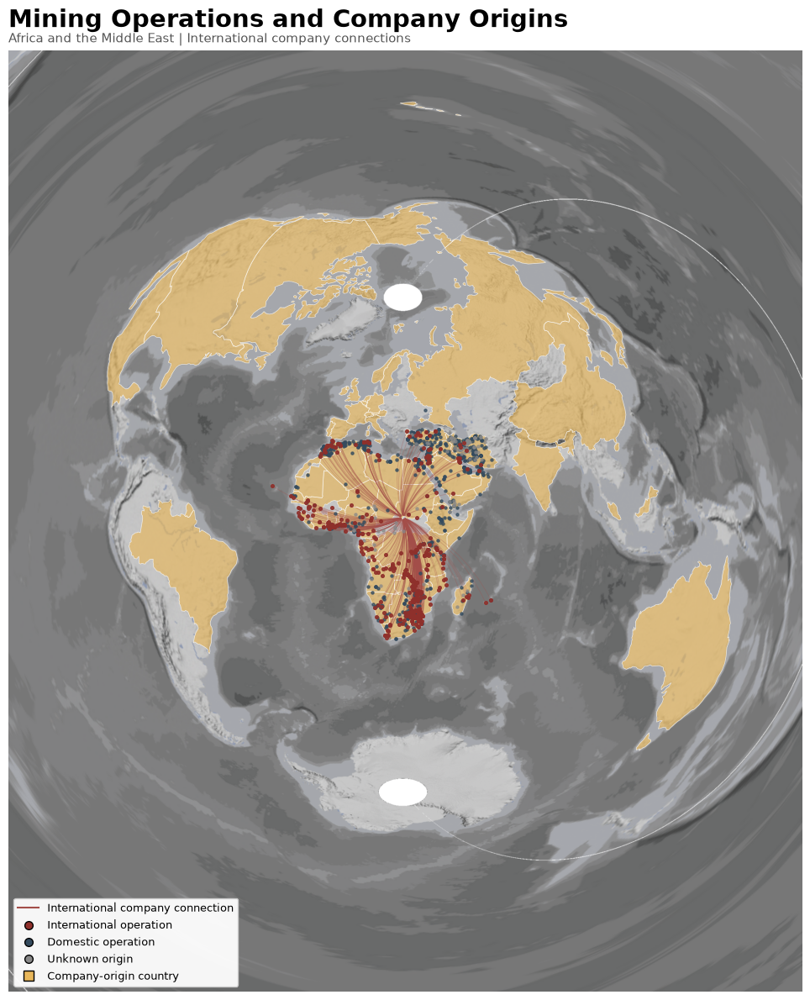

In [57]:

import os
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D


target_crs = (
    "+proj=aeqd +lat_0=10 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

mines_projected = mines_for_map.to_crs(target_crs)
international_projected = international_mines.to_crs(target_crs)
origins_projected = matched_countries.to_crs(target_crs)

origin_points_projected = origin_points.to_crs(target_crs)

bounds = np.array([
    mines_projected.total_bounds,
    origins_projected.total_bounds
])

xmin = bounds[:, 0].min()
ymin = bounds[:, 1].min()
xmax = bounds[:, 2].max()
ymax = bounds[:, 3].max()

x_padding = (xmax - xmin) * 0.06
y_padding = (ymax - ymin) * 0.06

xmin -= x_padding
xmax += x_padding
ymin -= y_padding
ymax += y_padding


fig, ax = plt.subplots(figsize=(16, 12))

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/"
    f"tiles/256/{{z}}/{{x}}/{{y}}"
    f"?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=2,
    attribution=False,
    reset_extent=False
)


origins_projected.plot(
    ax=ax,
    facecolor="#E8B75B",
    edgecolor="#FFFFFF",
    linewidth=0.55,
    alpha=0.65,
    zorder=2
)


for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["ORIGIN_GEOMETRY"]

    # Skip missing geometries
    if mine_point is None or origin_point is None:
        continue

    # Slight curve to distinguish the connections
    connection = FancyArrowPatch(
        (mine_point.x, mine_point.y),
        (origin_point.x, origin_point.y),
        connectionstyle="arc3,rad=0.18",
        arrowstyle="-",
        color="#A34E49",
        linewidth=0.65,
        alpha=0.28,
        zorder=3
    )

    ax.add_patch(connection)

international_projected.plot(
    ax=ax,
    color="#8F302B",
    markersize=7,
    alpha=0.9,
    zorder=5
)

domestic_projected = mines_projected[
    mines_projected["OWNERSHIP_RELATION"] == "Domestic"
]

domestic_projected.plot(
    ax=ax,
    color="#344B5E",
    markersize=5,
    alpha=0.75,
    zorder=4
)

unknown_projected = mines_projected[
    mines_projected["OWNERSHIP_RELATION"] == "Unknown"
]

unknown_projected.plot(
    ax=ax,
    color="#888888",
    markersize=5,
    alpha=0.65,
    zorder=4
)

ax.set_title(
    "Mining Operations and Company Origins",
    fontsize=21,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.text(
    0,
    1.005,
    "Africa and the Middle East | International company connections",
    transform=ax.transAxes,
    fontsize=11,
    color="#555555",
    va="bottom"
)

legend_elements = [
    Line2D(
        [0], [0],
        color="#A34E49",
        linewidth=1.5,
        label="International company connection"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#8F302B",
        markersize=7,
        label="International operation"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#344B5E",
        markersize=7,
        label="Domestic operation"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#888888",
        markersize=7,
        label="Unknown origin"
    ),
    Line2D(
        [0], [0],
        marker="s",
        color="none",
        markerfacecolor="#E8B75B",
        markersize=8,
        label="Company-origin country"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    fontsize=9
)

ax.set_axis_off()

plt.tight_layout()


os.makedirs("outputs", exist_ok=True)

plt.savefig(
    "outputs/mining_company_origins_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "outputs/mining_company_origins_map.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [56]:

target_crs = (
    "+proj=aeqd +lat_0=10 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

mines_projected = mines_for_map.to_crs(target_crs)

origins_projected = matched_countries.to_crs(target_crs)

origin_points_projected = origin_points.to_crs(target_crs)

origin_geometry_lookup = dict(
    zip(
        origin_points_projected["OWNER_ORIGIN_COUNTRY"],
        origin_points_projected.geometry
    )
)

mines_projected["ORIGIN_GEOMETRY"] = (
    mines_projected["OWNER_ORIGIN_COUNTRY"]
    .map(origin_geometry_lookup)
)

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International") &
    (mines_projected["ORIGIN_GEOMETRY"].notna())
].copy()

print("International operations:", len(international_projected))
print("Origin geometries successfully projected:",
      international_projected["ORIGIN_GEOMETRY"].notna().sum())

display(
    international_projected[
        ["SITE", "COUNTRY", "OWNER_ORIGIN_COUNTRY",
         "geometry", "ORIGIN_GEOMETRY"]
    ].head()
)

International operations: 466
Origin geometries successfully projected: 466


,SITE,COUNTRY,OWNER_ORIGIN_COUNTRY,geometry,ORIGIN_GEOMETRY
15,M'Sila,Algeria,Egypt,POINT (-1907958.445 2958472.338),POINT (439925.4787243289 1874633.8867859214)
19,El Hadjar,Algeria,Netherlands,POINT (-1593621.999 3048843.055),POINT (-1464188.0357037184 4769350.106136173)
38,"El Hadjar, Annaba",Algeria,Netherlands,POINT (-1593621.999 3048843.055),POINT (-1464188.0357037184 4769350.106136173)
39,"El Hadjar, Annaba",Algeria,Netherlands,POINT (-1593621.999 3048843.055),POINT (-1464188.0357037184 4769350.106136173)
40,"El Hadjar, Annaba",Algeria,Netherlands,POINT (-1593621.999 3048843.055),POINT (-1464188.0357037184 4769350.106136173)


International operations: 466
International origin countries: 51
Origin countries with polygons: 51


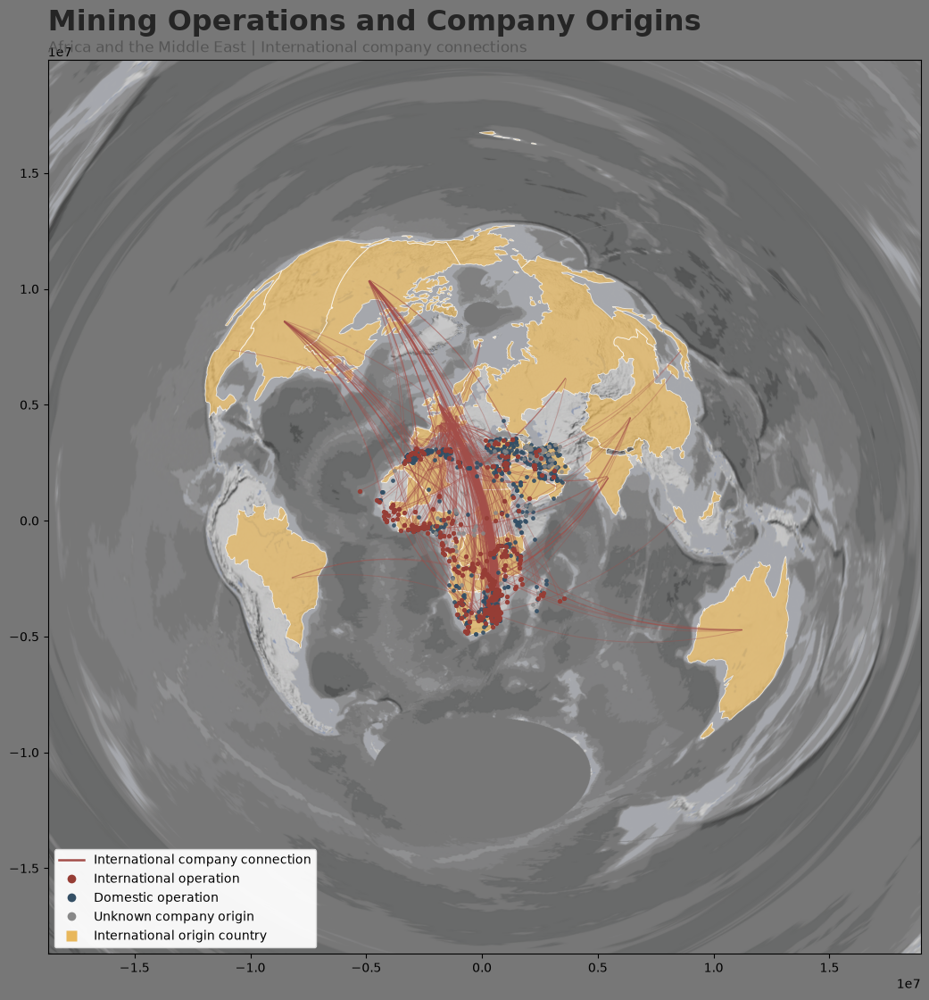

In [60]:

import os
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

# ==================================================
# 1. PROJECTION AND DATA PREPARATION
# ==================================================

target_crs = (
    "+proj=aeqd +lat_0=10 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

# Project mine locations
mines_projected = mines_for_map.to_crs(target_crs)

# Project origin points separately
origin_points_projected = origin_points.to_crs(target_crs)

# Create lookup for projected origin geometries
origin_geometry_lookup = dict(
    zip(
        origin_points_projected["OWNER_ORIGIN_COUNTRY"],
        origin_points_projected.geometry
    )
)

# Attach projected origin geometries to mine records
mines_projected["ORIGIN_GEOMETRY"] = (
    mines_projected["OWNER_ORIGIN_COUNTRY"]
    .map(origin_geometry_lookup)
)

# International operations only
international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International") &
    (mines_projected["ORIGIN_GEOMETRY"].notna())
].copy()

# Domestic and unknown operations
domestic_projected = mines_projected[
    mines_projected["OWNERSHIP_RELATION"] == "Domestic"
].copy()

unknown_projected = mines_projected[
    mines_projected["OWNERSHIP_RELATION"] == "Unknown"
].copy()


# ==================================================
# 2. FILTER ORIGIN COUNTRIES
# ==================================================

# Only countries that are origins of international operations
international_origin_names = (
    international_projected["OWNER_ORIGIN_COUNTRY"]
    .dropna()
    .unique()
)

# Highlight only those countries
origins_projected = matched_countries[
    matched_countries["OWNER_ORIGIN_COUNTRY"].isin(
        international_origin_names
    )
].to_crs(target_crs)

# Use only their representative points for map extent
international_origin_points = origin_points_projected[
    origin_points_projected["OWNER_ORIGIN_COUNTRY"].isin(
        international_origin_names
    )
].copy()

print("International operations:", len(international_projected))
print("International origin countries:", len(international_origin_names))
print("Origin countries with polygons:", len(origins_projected))


# ==================================================
# 3. MAP EXTENT
# ==================================================

mine_bounds = mines_projected.total_bounds
origin_bounds = international_origin_points.total_bounds

xmin = min(mine_bounds[0], origin_bounds[0])
ymin = min(mine_bounds[1], origin_bounds[1])
xmax = max(mine_bounds[2], origin_bounds[2])
ymax = max(mine_bounds[3], origin_bounds[3])

x_padding = (xmax - xmin) * 0.07
y_padding = (ymax - ymin) * 0.07

xmin -= x_padding
xmax += x_padding
ymin -= y_padding
ymax += y_padding


# ==================================================
# 4. CREATE FIGURE
# ==================================================

fig, ax = plt.subplots(figsize=(17, 13))

# Fill uncovered polar areas with ocean-like background
# Mapbox Web Mercator tiles do not extend to the poles.
ocean_color = "#777777"

fig.patch.set_facecolor(ocean_color)
ax.set_facecolor(ocean_color)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)


# ==================================================
# 5. MAPBOX LIGHT BASEMAP
# ==================================================

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/"
    f"tiles/256/{{z}}/{{x}}/{{y}}"
    f"?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=2,
    attribution=False,
    reset_extent=False
)


# ==================================================
# 6. HIGHLIGHT INTERNATIONAL ORIGIN COUNTRIES
# ==================================================

origins_projected.plot(
    ax=ax,
    facecolor="#E8B75B",
    edgecolor="#FFFFFF",
    linewidth=0.65,
    alpha=0.70,
    zorder=2
)


# ==================================================
# 7. CURVED INTERNATIONAL CONNECTIONS
# ==================================================

for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["ORIGIN_GEOMETRY"]

    if mine_point is None or origin_point is None:
        continue

    connection = FancyArrowPatch(
        (mine_point.x, mine_point.y),
        (origin_point.x, origin_point.y),
        connectionstyle="arc3,rad=0.16",
        arrowstyle="-",
        color="#A34E49",
        linewidth=0.75,
        alpha=0.35,
        zorder=3
    )

    ax.add_patch(connection)


# ==================================================
# 8. MINE-SITE DOTS
# ==================================================

international_projected.plot(
    ax=ax,
    color="#963D35",
    markersize=8,
    alpha=0.95,
    zorder=5
)

domestic_projected.plot(
    ax=ax,
    color="#344F65",
    markersize=6,
    alpha=0.85,
    zorder=4
)

unknown_projected.plot(
    ax=ax,
    color="#888888",
    markersize=6,
    alpha=0.75,
    zorder=4
)


# ==================================================
# 9. TITLE AND LEGEND
# ==================================================

ax.set_title(
    "Mining Operations and Company Origins",
    fontsize=23,
    fontweight="bold",
    loc="left",
    pad=24,
    color="#252525"
)

ax.text(
    0,
    1.005,
    "Africa and the Middle East | International company connections",
    transform=ax.transAxes,
    fontsize=12,
    color="#555555",
    va="bottom"
)

legend_elements = [
    Line2D(
        [0], [0],
        color="#A34E49",
        linewidth=1.8,
        label="International company connection"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#963D35",
        markeredgecolor="none",
        markersize=7,
        label="International operation"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#344F65",
        markeredgecolor="none",
        markersize=7,
        label="Domestic operation"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#888888",
        markeredgecolor="none",
        markersize=7,
        label="Unknown company origin"
    ),
    Line2D(
        [0], [0],
        marker="s",
        color="none",
        markerfacecolor="#E8B75B",
        markeredgecolor="none",
        markersize=9,
        label="International origin country"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    fontsize=10,
    edgecolor="#DDDDDD"
)




Production unit groups:


,Operations
CAPACITY_GROUP,
tonnes/year,370
NaN,53
barrels/year,23
carats/year,17
million cubic meters (period unspecified),2
cubic meters/year,1


Operations with unclassified capacity: 53
Origin countries highlighted: 51


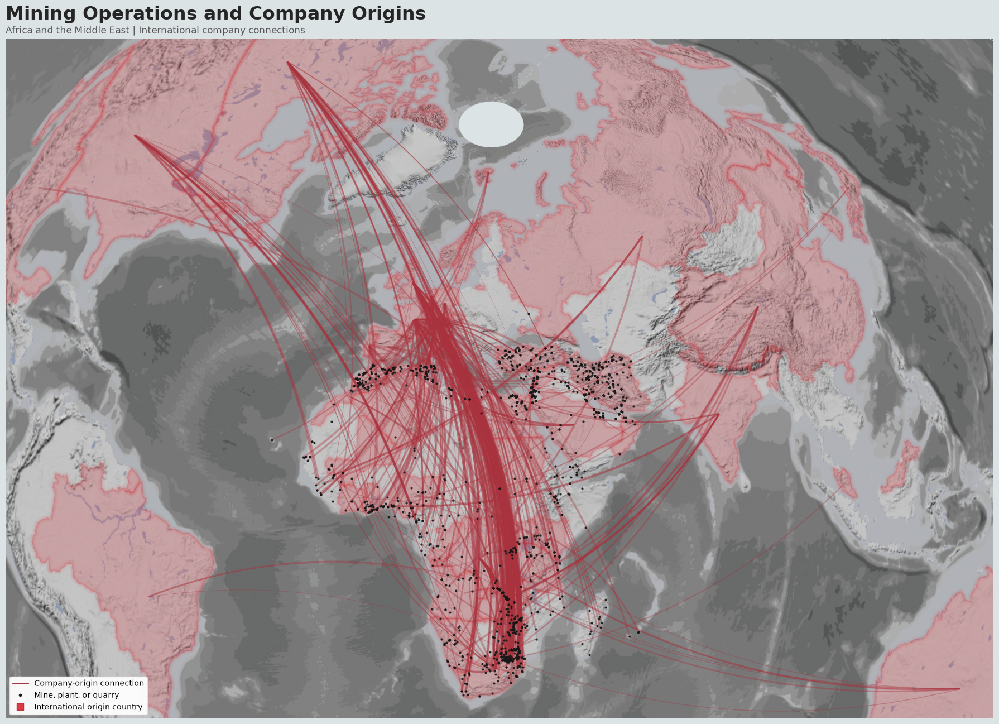

In [63]:

import os
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

target_crs = (
    "+proj=aeqd +lat_0=10 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

mines_projected = mines_for_map.to_crs(target_crs)
origin_points_projected = origin_points.to_crs(target_crs)

origin_geometry_lookup = dict(
    zip(
        origin_points_projected["OWNER_ORIGIN_COUNTRY"],
        origin_points_projected.geometry
    )
)

mines_projected["ORIGIN_GEOMETRY"] = (
    mines_projected["OWNER_ORIGIN_COUNTRY"]
    .map(origin_geometry_lookup)
)

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International") &
    (mines_projected["ORIGIN_GEOMETRY"].notna())
].copy()

domestic_projected = mines_projected[
    mines_projected["OWNERSHIP_RELATION"] == "Domestic"
].copy()

unknown_projected = mines_projected[
    mines_projected["OWNERSHIP_RELATION"] == "Unknown"
].copy()



def parse_capacity(value):
    if pd.isna(value):
        return np.nan

    value = str(value).replace(",", "").strip()

    match = re.search(r"[-+]?\d*\.?\d+", value)

    return float(match.group()) if match else np.nan


international_projected["CAPACITY_NUM"] = (
    international_projected["CAPACITY"].apply(parse_capacity)
)

def normalize_capacity(value, unit):

    if pd.isna(value) or pd.isna(unit):
        return np.nan, None

    unit = str(unit).strip().lower()
    capacity = float(value)

    if unit == "t / yr":
        return capacity, "tonnes/year"

    if unit == "kg / yr":
        return capacity / 1000, "tonnes/year"

    if unit == "42 gallon barrels / yr":
        return capacity, "barrels/year"

    if unit == "thousand 42 gallon barrels / yr":
        return capacity * 1000, "barrels/year"

    if unit == "million 42 gallon barrels / yr":
        return capacity * 1_000_000, "barrels/year"

    if unit == "42 gallon barrels / day":
        return capacity * 365, "barrels/year"

    if unit == "thousand 42 gallon barrels / day":
        return capacity * 1000 * 365, "barrels/year"

    if unit == "carats / yr":
        return capacity, "carats/year"

    if unit == "cubic meters/yr":
        return capacity, "cubic meters/year"

    if unit == "million cubic meters / yr":
        return capacity * 1_000_000, "cubic meters/year"

    if unit == "million cubic meters":
        return capacity * 1_000_000, "million cubic meters (period unspecified)"

    return np.nan, None


normalized = international_projected.apply(
    lambda row: normalize_capacity(
        row["CAPACITY_NUM"],
        row["UNITS"]
    ),
    axis=1
)

international_projected["NORMALIZED_CAPACITY"] = [
    item[0] for item in normalized
]

international_projected["CAPACITY_GROUP"] = [
    item[1] for item in normalized
]


# ==================================================
# 3. CALCULATE RELATIVE LINE WEIGHTS
# ==================================================

# Logarithmic scaling within comparable unit groups.
# Widths range from 0.45 to 2.8 points.

international_projected["LINE_WIDTH"] = 0.65

for group in international_projected["CAPACITY_GROUP"].dropna().unique():

    mask = international_projected["CAPACITY_GROUP"] == group

    values = international_projected.loc[
        mask, "NORMALIZED_CAPACITY"
    ]

    positive = values[values > 0]

    if len(positive) == 0:
        continue

    log_values = np.log10(positive)

    if log_values.max() == log_values.min():
        weights = pd.Series(
            1.5,
            index=positive.index
        )
    else:
        weights = (
            0.45
            + (
                (log_values - log_values.min()) /
                (log_values.max() - log_values.min())
            ) * 2.35
        )

    international_projected.loc[
        weights.index, "LINE_WIDTH"
    ] = weights

print("Production unit groups:")
display(
    international_projected["CAPACITY_GROUP"]
    .value_counts(dropna=False)
    .to_frame("Operations")
)

print(
    "Operations with unclassified capacity:",
    international_projected["CAPACITY_GROUP"].isna().sum()
)


# ==================================================
# 4. SELECT INTERNATIONAL ORIGIN COUNTRIES
# ==================================================

international_origin_names = (
    international_projected["OWNER_ORIGIN_COUNTRY"]
    .dropna()
    .unique()
)

origins_projected = matched_countries[
    matched_countries["OWNER_ORIGIN_COUNTRY"].isin(
        international_origin_names
    )
].to_crs(target_crs)

print("Origin countries highlighted:", len(origins_projected))


# ==================================================
# 5. MAP EXTENT
# ==================================================

mine_bounds = mines_projected.total_bounds
origin_bounds = origin_points_projected[
    origin_points_projected["OWNER_ORIGIN_COUNTRY"].isin(
        international_origin_names
    )
].total_bounds

xmin = min(mine_bounds[0], origin_bounds[0])
ymin = min(mine_bounds[1], origin_bounds[1])
xmax = max(mine_bounds[2], origin_bounds[2])
ymax = max(mine_bounds[3], origin_bounds[3])

# Tighter margins for a closer view
x_padding = (xmax - xmin) * 0.035
y_padding = (ymax - ymin) * 0.035

xmin -= x_padding
xmax += x_padding
ymin -= y_padding
ymax += y_padding


# ==================================================
# 6. CREATE FIGURE AND MAPBOX BASEMAP
# ==================================================

fig, ax = plt.subplots(figsize=(18, 13))

# Fill areas outside Mapbox tile coverage
ocean_color = "#DCE3E5"

fig.patch.set_facecolor(ocean_color)
ax.set_facecolor(ocean_color)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/"
    f"tiles/256/{{z}}/{{x}}/{{y}}"
    f"?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    attribution=False,
    reset_extent=False
)


# ==================================================
# 7. RED GLOWING ORIGIN COUNTRIES
# ==================================================

# Multiple translucent boundary layers create a soft glow.

origins_projected.boundary.plot(
    ax=ax,
    color="#D83B43",
    linewidth=8,
    alpha=0.055,
    zorder=2
)

origins_projected.boundary.plot(
    ax=ax,
    color="#D83B43",
    linewidth=4,
    alpha=0.12,
    zorder=2
)

origins_projected.plot(
    ax=ax,
    facecolor="#D83B43",
    edgecolor="#C72E3A",
    linewidth=0.8,
    alpha=0.24,
    zorder=3
)


# ==================================================
# 8. PRODUCTION-WEIGHTED CONNECTION LINES
# ==================================================

for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["ORIGIN_GEOMETRY"]

    if mine_point is None or origin_point is None:
        continue

    connection = FancyArrowPatch(
        (mine_point.x, mine_point.y),
        (origin_point.x, origin_point.y),
        connectionstyle="arc3,rad=0.16",
        arrowstyle="-",
        color="#A8323D",
        linewidth=row["LINE_WIDTH"],
        alpha=0.38,
        zorder=4
    )

    ax.add_patch(connection)


# ==================================================
# 9. ALL MINE LOCATIONS AS SMALL BLACK DOTS
# ==================================================

# Plot all operations with the same symbol and size.

mines_projected.plot(
    ax=ax,
    color="#171717",
    markersize=4,
    alpha=0.85,
    zorder=6
)


# ==================================================
# 10. TITLE AND LEGEND
# ==================================================

ax.set_title(
    "Mining Operations and Company Origins",
    fontsize=24,
    fontweight="bold",
    loc="left",
    pad=25,
    color="#252525"
)

ax.text(
    0,
    1.005,
    "Africa and the Middle East | International company connections",
    transform=ax.transAxes,
    fontsize=12,
    color="#555555",
    va="bottom"
)

legend_elements = [

    Line2D(
        [0], [0],
        color="#A8323D",
        linewidth=2,
        label="Company-origin connection"
    ),

    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#171717",
        markeredgecolor="none",
        markersize=4,
        label="Mine, plant, or quarry"
    ),

    Line2D(
        [0], [0],
        marker="s",
        color="none",
        markerfacecolor="#D83B43",
        markeredgecolor="#C72E3A",
        markersize=9,
        label="International origin country"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    fontsize=10,
    edgecolor="#DDDDDD"
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()




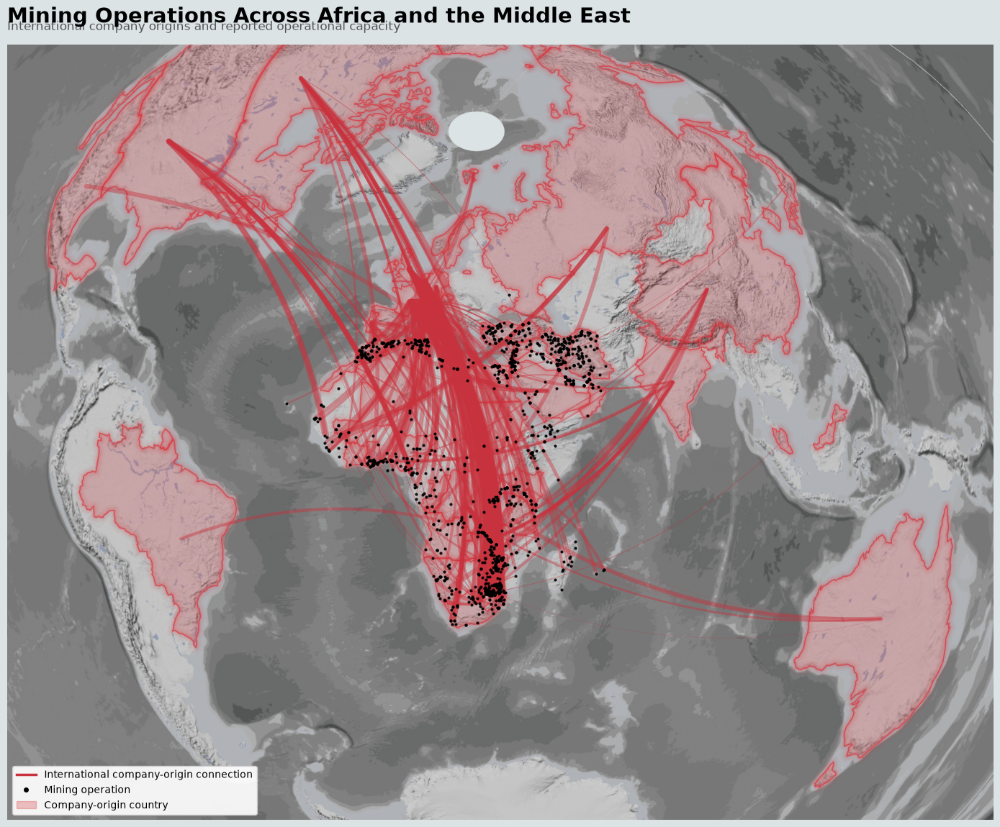

In [66]:

import os
import re
import math
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# --------------------------------------------------
# 1. PROJECTION
# --------------------------------------------------

target_crs = (
    "+proj=aeqd +lat_0=10 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

mines_projected = mines_for_map.to_crs(target_crs)
origin_points_projected = origin_points.to_crs(target_crs)

# Rebuild the origin geometry column in the projected CRS.
origin_geometry_lookup = dict(zip(
    origin_points_projected["OWNER_ORIGIN_COUNTRY"],
    origin_points_projected.geometry
))

mines_projected["ORIGIN_GEOMETRY"] = (
    mines_projected["OWNER_ORIGIN_COUNTRY"].map(
        origin_geometry_lookup
    )
)

# Select international operations with valid origin points.
international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International") &
    (mines_projected["ORIGIN_GEOMETRY"].notna())
].copy()

# --------------------------------------------------
# 2. PREPARE CAPACITY VALUES
# --------------------------------------------------

def parse_capacity(value):
    if value is None:
        return np.nan

    value = str(value).replace(",", "").strip()
    match = re.search(r"[-+]?\d*\.?\d+", value)

    if match:
        return float(match.group())

    return np.nan


international_projected["CAPACITY_NUM"] = (
    international_projected["CAPACITY"].apply(parse_capacity)
)

def normalize_capacity(row):
    capacity = row["CAPACITY_NUM"]
    units = str(row["UNITS"]).lower().strip()

    if pd.isna(capacity):
        return None, np.nan

    # Convert compatible units to a common unit within each group.
    if units == "t / yr":
        return "tonnes/year", capacity

    elif units == "kg / yr":
        return "tonnes/year", capacity / 1000

    elif units == "thousand 42 gallon barrels / yr":
        return "barrels/year", capacity * 1000

    elif units == "million 42 gallon barrels / yr":
        return "barrels/year", capacity * 1_000_000

    elif units == "42 gallon barrels / yr":
        return "barrels/year", capacity

    elif units == "42 gallon barrels / day":
        return "barrels/year", capacity * 365

    elif units == "thousand 42 gallon barrels / day":
        return "barrels/year", capacity * 1000 * 365

    elif units == "carats / yr":
        return "carats/year", capacity

    elif units == "cubic meters/yr":
        return "cubic meters/year", capacity

    elif units == "million cubic meters / yr":
        return "cubic meters/year", capacity * 1_000_000

    elif units == "million cubic meters":
        return "million cubic meters (period unspecified)", capacity

    else:
        return None, np.nan


normalized = international_projected.apply(
    normalize_capacity, axis=1
)

international_projected["CAPACITY_GROUP"] = [
    item[0] for item in normalized
]

international_projected["CAPACITY_NORMALIZED"] = [
    item[1] for item in normalized
]

# --------------------------------------------------
# 3. DRAMATIC LINE-WIDTH SCALING
# --------------------------------------------------

international_projected["LINE_WIDTH"] = 0.08

for group in international_projected["CAPACITY_GROUP"].dropna().unique():

    group_mask = (
        international_projected["CAPACITY_GROUP"] == group
    )

    values = international_projected.loc[
        group_mask, "CAPACITY_NORMALIZED"
    ]

    valid = values.notna() & (values > 0)

    if valid.sum() == 0:
        continue

    log_values = np.log10(values[valid])

    log_min = log_values.min()
    log_max = log_values.max()

    if log_max == log_min:
        scaled = np.full(len(log_values), 0.5)
    else:
        scaled = (
            (log_values - log_min) /
            (log_max - log_min)
        )

    # Strong nonlinear contrast.
    widths = 0.08 + (scaled ** 2.2) * (5.5 - 0.08)

    international_projected.loc[
        values[valid].index, "LINE_WIDTH"
    ] = widths

# --------------------------------------------------
# 4. PROJECT ORIGIN COUNTRY POLYGONS
# --------------------------------------------------

international_origins = (
    international_projected["OWNER_ORIGIN_COUNTRY"]
    .dropna()
    .unique()
)

origins_projected = matched_countries[
    matched_countries["OWNER_ORIGIN_COUNTRY"].isin(
        international_origins
    )
].to_crs(target_crs)

# --------------------------------------------------
# 5. MAP EXTENT
# --------------------------------------------------

mine_bounds = mines_projected.total_bounds
point_bounds = origin_points_projected[
    origin_points_projected["OWNER_ORIGIN_COUNTRY"].isin(
        international_origins
    )
].total_bounds
polygon_bounds = origins_projected.total_bounds

xmin = min(mine_bounds[0], point_bounds[0], polygon_bounds[0])
ymin = min(mine_bounds[1], point_bounds[1], polygon_bounds[1])
xmax = max(mine_bounds[2], point_bounds[2], polygon_bounds[2])
ymax = max(mine_bounds[3], point_bounds[3])

# Small margin around the full extent.
x_margin = (xmax - xmin) * 0.045
y_margin = (ymax - ymin) * 0.045

xmin -= x_margin
xmax += x_margin
ymin -= y_margin
ymax += y_margin

# --------------------------------------------------
# 6. CREATE FIGURE AND BACKGROUND
# --------------------------------------------------

ocean_color = "#DCE3E5"

fig, ax = plt.subplots(figsize=(18, 14))

fig.patch.set_facecolor(ocean_color)
ax.set_facecolor(ocean_color)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 7. MAPBOX LIGHT BASEMAP
# --------------------------------------------------

MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

# Uses the MAPBOX_TOKEN already stored in your notebook.
mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/tiles/256/"
    f"{{z}}/{{x}}/{{y}}?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    reset_extent=False,
    attribution=False
)

# Reapply the intended extent after loading tiles.
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 8. HIGHLIGHT ORIGIN COUNTRIES
# --------------------------------------------------

# Soft red fill.
origins_projected.plot(
    ax=ax,
    facecolor="#D83B43",
    edgecolor="none",
    alpha=0.22,
    zorder=3
)

# Multiple boundary passes create a subtle glow.
for linewidth, alpha in [
    (12, 0.035),
    (8, 0.07),
    (4, 0.13),
    (1.2, 0.75)
]:
    origins_projected.boundary.plot(
        ax=ax,
        color="#D83B43",
        linewidth=linewidth,
        alpha=alpha,
        zorder=4
    )

# --------------------------------------------------
# 9. CURVED COMPANY-ORIGIN CONNECTIONS
# --------------------------------------------------

for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["ORIGIN_GEOMETRY"]

    if mine_point is None or origin_point is None:
        continue

    if mine_point.is_empty or origin_point.is_empty:
        continue

    start = (mine_point.x, mine_point.y)
    end = (origin_point.x, origin_point.y)

    connection = FancyArrowPatch(
        start,
        end,
        connectionstyle="arc3,rad=0.16",
        arrowstyle="-",
        linewidth=row["LINE_WIDTH"],
        color="#C8323D",
        alpha=0.42,
        zorder=5,
        capstyle="round"
    )

    ax.add_patch(connection)

# --------------------------------------------------
# 10. ALL MINE LOCATIONS
# --------------------------------------------------

mines_projected.plot(
    ax=ax,
    color="black",
    markersize=4,
    alpha=0.85,
    zorder=6
)

# --------------------------------------------------
# 11. TITLE AND LEGEND
# --------------------------------------------------

ax.set_title(
    "Mining Operations Across Africa and the Middle East",
    fontsize=21,
    fontweight="bold",
    loc="left",
    pad=22
)

ax.text(
    0,
    1.015,
    "International company origins and reported operational capacity",
    transform=ax.transAxes,
    fontsize=12,
    color="#555555",
    va="bottom"
)

legend_elements = [
    Line2D(
        [0], [0],
        color="#C8323D",
        linewidth=2.5,
        label="International company-origin connection"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="black",
        markersize=4,
        linestyle="None",
        label="Mining operation"
    ),
    Patch(
        facecolor="#D83B43",
        edgecolor="#D83B43",
        alpha=0.3,
        label="Company-origin country"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="white",
    framealpha=0.92,
    fontsize=10
)

ax.set_axis_off()



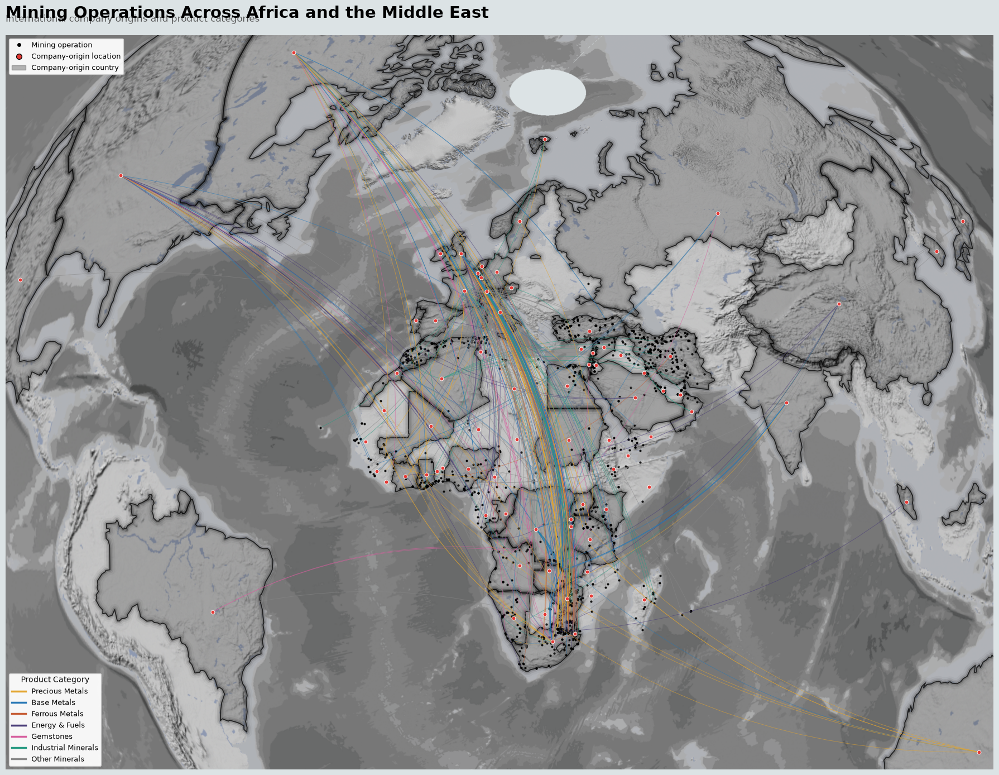

In [75]:

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D

# --------------------------------------------------
# 1. AZIMUTHAL PROJECTION
# --------------------------------------------------

target_crs = (
    "+proj=aeqd +lat_0=-5 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

mines_projected = mines_for_map.to_crs(target_crs)
origin_points_projected = origin_points.to_crs(target_crs)

# Rebuild origin geometry in projected coordinates.
origin_geometry_lookup = dict(zip(
    origin_points_projected["OWNER_ORIGIN_COUNTRY"],
    origin_points_projected.geometry
))

mines_projected["ORIGIN_GEOMETRY"] = (
    mines_projected["OWNER_ORIGIN_COUNTRY"].map(
        origin_geometry_lookup
    )
)

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International") &
    (mines_projected["ORIGIN_GEOMETRY"].notna())
].copy()

# --------------------------------------------------
# 2. CLASSIFY PRODUCTS
# --------------------------------------------------

def classify_commodity(value):

    commodity = str(value).lower().strip()

    precious_metals = [
        "gold", "silver", "platinum",
        "palladium", "rhodium"
    ]

    gemstones = [
        "diamond", "diamonds", "gemstone",
        "gemstones", "emerald", "ruby",
        "sapphire"
    ]

    ferrous_metals = [
        "iron ore", "iron", "manganese",
        "chromium", "chrome", "chromite",
        "vanadium", "molybdenum"
    ]

    base_metals = [
        "copper", "nickel", "zinc",
        "lead", "tin", "cobalt",
        "aluminium", "aluminum", "bauxite"
    ]

    energy = [
        "coal", "uranium", "oil",
        "petroleum", "natural gas",
        "gas", "crude", "lignite"
    ]

    industrial = [
        "phosphate", "potash", "salt",
        "gypsum", "limestone", "sulfur",
        "sulphur", "fluorspar", "fluorite",
        "talc", "feldspar", "silica",
        "silicon", "kaolin", "clay",
        "barite", "baryte", "magnesite",
        "asbestos", "mica", "graphite"
    ]

    if any(item in commodity for item in precious_metals):
        return "Precious Metals"

    elif any(item in commodity for item in gemstones):
        return "Gemstones"

    elif any(item in commodity for item in ferrous_metals):
        return "Ferrous Metals"

    elif any(item in commodity for item in base_metals):
        return "Base Metals"

    elif any(item in commodity for item in energy):
        return "Energy & Fuels"

    elif any(item in commodity for item in industrial):
        return "Industrial Minerals"

    else:
        return "Other Minerals"


international_projected["PRODUCT_CATEGORY"] = (
    international_projected["COMMODITY"]
    .fillna("Unknown")
    .apply(classify_commodity)
)

# --------------------------------------------------
# 3. CATEGORY COLORS
# --------------------------------------------------

category_order = [
    "Precious Metals",
    "Base Metals",
    "Ferrous Metals",
    "Energy & Fuels",
    "Gemstones",
    "Industrial Minerals",
    "Other Minerals"
]

category_colors = {
    "Precious Metals": "#E3A52F",
    "Base Metals": "#2878B5",
    "Ferrous Metals": "#C65D35",
    "Energy & Fuels": "#493C78",
    "Gemstones": "#D65F9E",
    "Industrial Minerals": "#299B83",
    "Other Minerals": "#888888"
}

international_projected["LINE_COLOR"] = (
    international_projected["PRODUCT_CATEGORY"].map(
        category_colors
    )
)

# --------------------------------------------------
# 4. ORIGIN COUNTRY POLYGONS
# --------------------------------------------------

international_origins = (
    international_projected["OWNER_ORIGIN_COUNTRY"]
    .dropna()
    .unique()
)

origins_projected = matched_countries[
    matched_countries["OWNER_ORIGIN_COUNTRY"].isin(
        international_origins
    )
].to_crs(target_crs)

# --------------------------------------------------
# 5. MAP EXTENT
# --------------------------------------------------

# Include all mine locations and all matched origin points.
mine_bounds = mines_projected.total_bounds
origin_bounds = origin_points_projected.total_bounds

xmin = min(mine_bounds[0], origin_bounds[0])
ymin = min(mine_bounds[1], origin_bounds[1])
xmax = max(mine_bounds[2], origin_bounds[2])
ymax = max(mine_bounds[3], origin_bounds[3])

# Slightly tighter margins.
x_margin = (xmax - xmin) * 0.015
y_margin = (ymax - ymin) * 0.025

xmin -= x_margin
xmax += x_margin
ymin -= y_margin
ymax += y_margin

# --------------------------------------------------
# 6. FIGURE AND BACKGROUND
# --------------------------------------------------

ocean_color = "#DCE3E5"

fig, ax = plt.subplots(figsize=(18, 14))

fig.patch.set_facecolor(ocean_color)
ax.set_facecolor(ocean_color)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 7. MAPBOX LIGHT BASEMAP
# --------------------------------------------------

MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/tiles/256/"
    f"{{z}}/{{x}}/{{y}}?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    reset_extent=False,
    attribution=False
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 8. ORIGIN COUNTRY FILL AND BLACK GLOW
# --------------------------------------------------

# Fill the entire origin-country polygons.
origins_projected.plot(
    ax=ax,
    facecolor="#171717",
    edgecolor="none",
    alpha=0.20,
    zorder=3
)

# Layered black boundary glow.
for linewidth, alpha in [
    (14, 0.035),
    (9, 0.08),
    (5, 0.16),
    (1.3, 0.85)
]:
    origins_projected.boundary.plot(
        ax=ax,
        color="#111111",
        linewidth=linewidth,
        alpha=alpha,
        zorder=4
    )

# --------------------------------------------------
# 9. MINE POINTS
# --------------------------------------------------

mines_projected.plot(
    ax=ax,
    color="black",
    markersize=4,
    alpha=0.85,
    zorder=5
)

# --------------------------------------------------
# 10. PRODUCT-CATEGORY CONNECTIONS
# --------------------------------------------------

for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["ORIGIN_GEOMETRY"]

    if mine_point is None or origin_point is None:
        continue

    if mine_point.is_empty or origin_point.is_empty:
        continue

    start = (mine_point.x, mine_point.y)
    end = (origin_point.x, origin_point.y)

    connection = FancyArrowPatch(
        start,
        end,
        connectionstyle="arc3,rad=0.16",
        arrowstyle="-",
        linewidth=0.65,
        color=row["LINE_COLOR"],
        alpha=0.58,
        zorder=6,
        capstyle="round"
    )

    ax.add_patch(connection)

# --------------------------------------------------
# 11. RED ORIGIN-COUNTRY POINTS
# --------------------------------------------------

origin_points_projected.plot(
    ax=ax,
    color="#E53935",
    markersize=24,
    edgecolor="white",
    linewidth=0.65,
    alpha=1,
    zorder=7
)

# --------------------------------------------------
# 12. TITLE AND SUBTITLE
# --------------------------------------------------

ax.set_title(
    "Mining Operations Across Africa and the Middle East",
    fontsize=21,
    fontweight="bold",
    loc="left",
    pad=22
)

ax.text(
    0,
    1.015,
    "International company origins and product categories",
    transform=ax.transAxes,
    fontsize=12,
    color="#555555",
    va="bottom"
)

# --------------------------------------------------
# 13. LEGENDS
# --------------------------------------------------

category_handles = [
    Line2D(
        [0], [0],
        color=category_colors[category],
        linewidth=2.5,
        label=category
    )
    for category in category_order
    if category in international_projected["PRODUCT_CATEGORY"].values
]

symbol_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="black",
        markersize=4,
        linestyle="None",
        label="Mining operation"
    ),
    Line2D(
        [0], [0],
        marker="o",
        markerfacecolor="#E53935",
        markeredgecolor="black",
        markersize=7,
        linestyle="None",
        label="Company-origin location"
    ),
    Patch(
        facecolor="#171717",
        edgecolor="#111111",
        alpha=0.3,
        label="Company-origin country"
    )
]

category_legend = ax.legend(
    handles=category_handles,
    title="Product Category",
    loc="lower left",
    bbox_to_anchor=(0, 0),
    frameon=True,
    facecolor="white",
    framealpha=0.94,
    fontsize=9,
    title_fontsize=10
)

ax.add_artist(category_legend)

ax.legend(
    handles=symbol_handles,
    loc="upper left",
    frameon=True,
    facecolor="white",
    framealpha=0.94,
    fontsize=9
)

# --------------------------------------------------
# 14. FINAL DISPLAY AND EXPORT
# --------------------------------------------------

ax.set_axis_off()

plt.tight_layout()

os.makedirs("outputs", exist_ok=True)

plt.savefig(
    "outputs/mining_company_origins_by_product_category.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    "outputs/mining_company_origins_by_product_category.pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


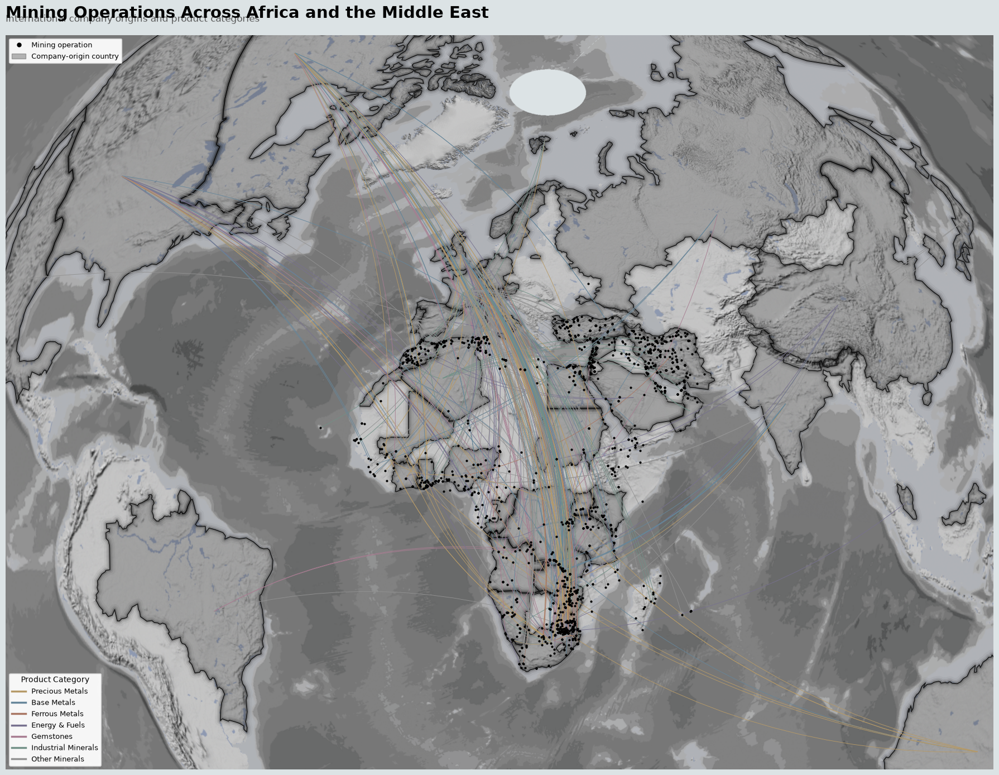

In [79]:

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D

# --------------------------------------------------
# 1. AZIMUTHAL PROJECTION
# --------------------------------------------------

target_crs = (
    "+proj=aeqd +lat_0=-5 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

mines_projected = mines_for_map.to_crs(target_crs)
origin_points_projected = origin_points.to_crs(target_crs)

# Rebuild origin geometry in projected coordinates.
origin_geometry_lookup = dict(zip(
    origin_points_projected["OWNER_ORIGIN_COUNTRY"],
    origin_points_projected.geometry
))

mines_projected["ORIGIN_GEOMETRY"] = (
    mines_projected["OWNER_ORIGIN_COUNTRY"].map(
        origin_geometry_lookup
    )
)

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International") &
    (mines_projected["ORIGIN_GEOMETRY"].notna())
].copy()

# --------------------------------------------------
# 2. CLASSIFY PRODUCTS
# --------------------------------------------------

def classify_commodity(value):

    commodity = str(value).lower().strip()

    precious_metals = [
        "gold", "silver", "platinum",
        "palladium", "rhodium"
    ]

    gemstones = [
        "diamond", "diamonds", "gemstone",
        "gemstones", "emerald", "ruby",
        "sapphire"
    ]

    ferrous_metals = [
        "iron ore", "iron", "manganese",
        "chromium", "chrome", "chromite",
        "vanadium", "molybdenum"
    ]

    base_metals = [
        "copper", "nickel", "zinc",
        "lead", "tin", "cobalt",
        "aluminium", "aluminum", "bauxite"
    ]

    energy = [
        "coal", "uranium", "oil",
        "petroleum", "natural gas",
        "gas", "crude", "lignite"
    ]

    industrial = [
        "phosphate", "potash", "salt",
        "gypsum", "limestone", "sulfur",
        "sulphur", "fluorspar", "fluorite",
        "talc", "feldspar", "silica",
        "silicon", "kaolin", "clay",
        "barite", "baryte", "magnesite",
        "asbestos", "mica", "graphite"
    ]

    if any(item in commodity for item in precious_metals):
        return "Precious Metals"

    elif any(item in commodity for item in gemstones):
        return "Gemstones"

    elif any(item in commodity for item in ferrous_metals):
        return "Ferrous Metals"

    elif any(item in commodity for item in base_metals):
        return "Base Metals"

    elif any(item in commodity for item in energy):
        return "Energy & Fuels"

    elif any(item in commodity for item in industrial):
        return "Industrial Minerals"

    else:
        return "Other Minerals"


international_projected["PRODUCT_CATEGORY"] = (
    international_projected["COMMODITY"]
    .fillna("Unknown")
    .apply(classify_commodity)
)

# --------------------------------------------------
# 3. MUTED CATEGORY COLORS
# --------------------------------------------------

category_order = [
    "Precious Metals",
    "Base Metals",
    "Ferrous Metals",
    "Energy & Fuels",
    "Gemstones",
    "Industrial Minerals",
    "Other Minerals"
]

category_colors = {
    "Precious Metals": "#B69A68",      # muted gold
    "Base Metals": "#66869A",          # slate blue
    "Ferrous Metals": "#A87562",       # muted terracotta
    "Energy & Fuels": "#77718F",       # dusty purple
    "Gemstones": "#A77D91",            # dusty rose
    "Industrial Minerals": "#729187",  # muted sage
    "Other Minerals": "#929292"        # soft gray
}

international_projected["LINE_COLOR"] = (
    international_projected["PRODUCT_CATEGORY"].map(
        category_colors
    )
)
# --------------------------------------------------
# 4. ORIGIN COUNTRY POLYGONS
# --------------------------------------------------

international_origins = (
    international_projected["OWNER_ORIGIN_COUNTRY"]
    .dropna()
    .unique()
)

origins_projected = matched_countries[
    matched_countries["OWNER_ORIGIN_COUNTRY"].isin(
        international_origins
    )
].to_crs(target_crs)

# --------------------------------------------------
# 5. MAP EXTENT
# --------------------------------------------------

# Include all mine locations and all matched origin points.
mine_bounds = mines_projected.total_bounds
origin_bounds = origin_points_projected.total_bounds

xmin = min(mine_bounds[0], origin_bounds[0])
ymin = min(mine_bounds[1], origin_bounds[1])
xmax = max(mine_bounds[2], origin_bounds[2])
ymax = max(mine_bounds[3], origin_bounds[3])

# Map margins.
x_margin = (xmax - xmin) * 0.015
y_margin = (ymax - ymin) * 0.025

xmin -= x_margin
xmax += x_margin
ymin -= y_margin
ymax += y_margin

# --------------------------------------------------
# 6. FIGURE AND BACKGROUND
# --------------------------------------------------

ocean_color = "#DCE3E5"

fig, ax = plt.subplots(figsize=(18, 14))

fig.patch.set_facecolor(ocean_color)
ax.set_facecolor(ocean_color)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 7. MAPBOX LIGHT BASEMAP
# --------------------------------------------------

MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/tiles/256/"
    f"{{z}}/{{x}}/{{y}}?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    reset_extent=False,
    attribution=False
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 8. ORIGIN COUNTRY FILL AND BLACK GLOW
# --------------------------------------------------

# Fill the entire origin-country polygons.
origins_projected.plot(
    ax=ax,
    facecolor="#171717",
    edgecolor="none",
    alpha=0.20,
    zorder=3
)

# Layered black boundary glow.
for linewidth, alpha in [
    (14, 0.035),
    (9, 0.08),
    (5, 0.16),
    (1.3, 0.85)
]:
    origins_projected.boundary.plot(
        ax=ax,
        color="#111111",
        linewidth=linewidth,
        alpha=alpha,
        zorder=4
    )

# --------------------------------------------------
# 9. ALL MINING OPERATION POINTS
# --------------------------------------------------

mines_projected.plot(
    ax=ax,
    color="black",
    marker="o",
    markersize=4,
    alpha=1,
    zorder=7
)
# --------------------------------------------------
# 10. PRODUCT-CATEGORY CONNECTIONS
# --------------------------------------------------

for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["ORIGIN_GEOMETRY"]

    if mine_point is None or origin_point is None:
        continue

    if mine_point.is_empty or origin_point.is_empty:
        continue

    start = (mine_point.x, mine_point.y)
    end = (origin_point.x, origin_point.y)

    connection = FancyArrowPatch(
        start,
        end,
        connectionstyle="arc3,rad=0.16",
        arrowstyle="-",
        linewidth=0.65,
        color=row["LINE_COLOR"],
        alpha=1,
        zorder=6,
        capstyle="round"
    )

    ax.add_patch(connection)

# --------------------------------------------------
# 11. TITLE AND SUBTITLE
# --------------------------------------------------

ax.set_title(
    "Mining Operations Across Africa and the Middle East",
    fontsize=21,
    fontweight="bold",
    loc="left",
    pad=22
)

ax.text(
    0,
    1.015,
    "International company origins and product categories",
    transform=ax.transAxes,
    fontsize=12,
    color="#555555",
    va="bottom"
)

# --------------------------------------------------
# 12. LEGENDS
# --------------------------------------------------

category_handles = [
    Line2D(
        [0], [0],
        color=category_colors[category],
        linewidth=2.5,
        label=category
    )
    for category in category_order
    if category in international_projected["PRODUCT_CATEGORY"].values
]

symbol_handles = [
    Line2D(
        [0], [0],
        marker="o",
        markerfacecolor="black",
        markeredgecolor="black",
        markersize=5,
        linestyle="None",
        label="Mining operation"
    ),
    Patch(
        facecolor="#171717",
        edgecolor="#111111",
        alpha=0.3,
        label="Company-origin country"
    )
]
category_legend = ax.legend(
    handles=category_handles,
    title="Product Category",
    loc="lower left",
    bbox_to_anchor=(0, 0),
    frameon=True,
    facecolor="white",
    framealpha=0.94,
    fontsize=9,
    title_fontsize=10
)

ax.add_artist(category_legend)

ax.legend(
    handles=symbol_handles,
    loc="upper left",
    frameon=True,
    facecolor="white",
    framealpha=0.94,
    fontsize=9
)

# --------------------------------------------------
# 13. FINAL DISPLAY AND EXPORT
# --------------------------------------------------

ax.set_axis_off()

plt.tight_layout()

os.makedirs("outputs", exist_ok=True)

plt.savefig(
    "outputs/mining_company_origins_by_product_category.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    "outputs/mining_company_origins_by_product_category.pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:752: RuntimeWarning: invalid value encountered in make_valid
  return lib.make_valid(geometry, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:752: RuntimeWarning: invalid value encountered in make_valid
  return lib.make_valid(geometry, **kwargs)


Countries without continent: Empty DataFrame
Columns: [OWNER_ORIGIN_COUNTRY, ADMIN]
Index: []


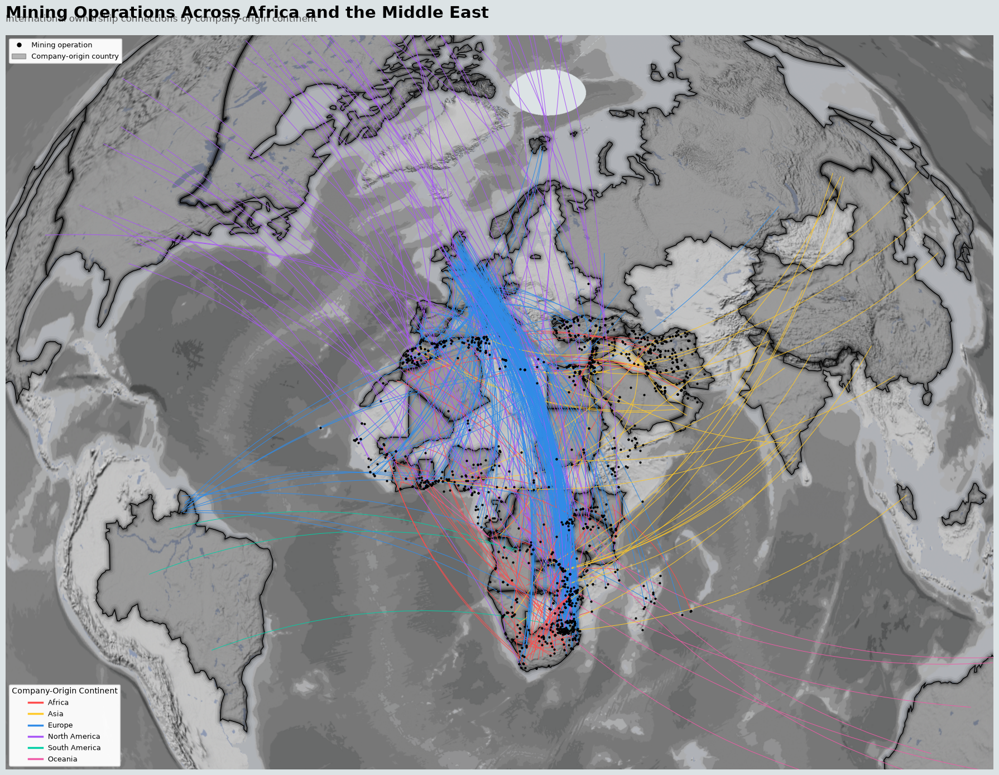

In [84]:

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from shapely.geometry import Point, Polygon, MultiPolygon, GeometryCollection
from shapely import make_valid
from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D

# --------------------------------------------------
# 1. AZIMUTHAL PROJECTION
# --------------------------------------------------

target_crs = (
    "+proj=aeqd +lat_0=-5 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

mines_projected = mines_for_map.to_crs(target_crs)
origin_points_projected = origin_points.to_crs(target_crs)

# --------------------------------------------------
# 2. ORIGIN COUNTRY POLYGONS
# --------------------------------------------------

international_origins = (
    mines_projected.loc[
        mines_projected["OWNERSHIP_RELATION"] == "International",
        "OWNER_ORIGIN_COUNTRY"
    ]
    .dropna()
    .unique()
)

origins_projected = matched_countries[
    matched_countries["OWNER_ORIGIN_COUNTRY"].isin(
        international_origins
    )
].to_crs(target_crs).copy()

# --------------------------------------------------
# 3. REPAIR COUNTRY GEOMETRIES AND FILL INTERIOR HOLES
# --------------------------------------------------

def extract_polygons(geometry):
    """Return all polygon parts from a geometry."""

    if geometry is None or geometry.is_empty:
        return []

    if geometry.geom_type == "Polygon":
        return [geometry]

    if geometry.geom_type in ["MultiPolygon", "GeometryCollection"]:
        polygons = []

        for part in geometry.geoms:
            polygons.extend(extract_polygons(part))

        return polygons

    return []



def remove_polygon_holes(geometry):

    if geometry is None or geometry.is_empty:
        return geometry

    try:
        if not geometry.is_valid:
            geometry = make_valid(geometry)

        polygon_parts = extract_polygons(geometry)

        filled_polygons = []

        for polygon in polygon_parts:

            if polygon.is_empty:
                continue

            filled = Polygon(polygon.exterior)

            if not filled.is_empty and filled.is_valid:
                filled_polygons.append(filled)

        if len(filled_polygons) == 0:
            return geometry

        if len(filled_polygons) == 1:
            return filled_polygons[0]

        return MultiPolygon(filled_polygons)

    except Exception as error:
        print("Could not repair geometry:", error)
        return geometry


origins_projected["geometry"] = (
    origins_projected.geometry.apply(remove_polygon_holes)
)

origins_projected = origins_projected[
    origins_projected.geometry.notna() &
    ~origins_projected.geometry.is_empty
].copy()


# --------------------------------------------------
# 4. CONTINENT COLORS
# --------------------------------------------------

# Build a country-to-continent lookup from the original
# Natural Earth world GeoDataFrame.

continent_lookup = dict(zip(
    world["ADMIN"],
    world["CONTINENT"]
))

# Match origin countries using the Natural Earth country names.
# matched_countries uses OWNER_ORIGIN_COUNTRY, so use its
# corresponding ADMIN field to retrieve the continent.

origins_projected["CONTINENT"] = (
    origins_projected["ADMIN"].map(continent_lookup)
)

# Check for countries that could not be assigned a continent.
print(
    "Countries without continent:",
    origins_projected.loc[
        origins_projected["CONTINENT"].isna(),
        ["OWNER_ORIGIN_COUNTRY", "ADMIN"]
    ]
)

continent_colors = {
    "Africa": "#FF4B4B",
    "Asia": "#FFC928",
    "Europe": "#318CE7",
    "North America": "#A855F7",
    "South America": "#00CFA6",
    "Oceania": "#F05AA6",
    "Antarctica": "#888888"
}

# Create country-to-continent lookup.
continent_lookup = dict(zip(
    origins_projected["OWNER_ORIGIN_COUNTRY"],
    origins_projected["CONTINENT"]
))

# Create country-to-polygon lookup.
origin_polygon_lookup = dict(zip(
    origins_projected["OWNER_ORIGIN_COUNTRY"],
    origins_projected.geometry
))

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International") &
    (mines_projected["OWNER_ORIGIN_COUNTRY"].notna())
].copy()

international_projected["ORIGIN_CONTINENT"] = (
    international_projected["OWNER_ORIGIN_COUNTRY"].map(
        continent_lookup
    )
)

international_projected["LINE_COLOR"] = (
    international_projected["ORIGIN_CONTINENT"].map(
        continent_colors
    )
)

# --------------------------------------------------
# 5. RANDOM CONNECTION POINTS INSIDE ORIGIN COUNTRIES
# --------------------------------------------------

# Fixed seed means the same random endpoints are used
# every time the notebook is run.
rng = np.random.default_rng(42)


def random_point_inside(geometry, rng):
    """
    Select a random point inside a country polygon.
    For countries with multiple separated polygon parts,
    larger parts have a greater chance of being selected.
    """

    if geometry is None or geometry.is_empty:
        return None

    polygon_parts = extract_polygons(make_valid(geometry))

    if not polygon_parts:
        return None

    # Weight polygon parts by their area.
    areas = np.array([polygon.area for polygon in polygon_parts])

    if areas.sum() == 0:
        return None

    probabilities = areas / areas.sum()

    selected_polygon = rng.choice(
        polygon_parts,
        p=probabilities
    )

    minx, miny, maxx, maxy = selected_polygon.bounds

    # Rejection sampling: keep points that fall inside the polygon.
    for _ in range(2000):

        x = rng.uniform(minx, maxx)
        y = rng.uniform(miny, maxy)

        candidate = Point(x, y)

        if selected_polygon.covers(candidate):
            return candidate

    # Fallback if random sampling does not find a point.
    return selected_polygon.representative_point()


# Give every international mine its own random endpoint
# within its company's country of origin.
international_projected["RANDOM_ORIGIN_POINT"] = (
    international_projected["OWNER_ORIGIN_COUNTRY"].apply(
        lambda country: random_point_inside(
            origin_polygon_lookup.get(country),
            rng
        )
    )
)

international_projected = international_projected[
    international_projected["RANDOM_ORIGIN_POINT"].notna()
].copy()

# --------------------------------------------------
# 6. MAP EXTENT
# --------------------------------------------------

# Keep the extent based on mine locations and origin-country
# representative points, rather than the full bounds of large
# countries such as Russia or the United States.
mine_bounds = mines_projected.total_bounds
origin_bounds = origin_points_projected.total_bounds

xmin = min(mine_bounds[0], origin_bounds[0])
ymin = min(mine_bounds[1], origin_bounds[1])
xmax = max(mine_bounds[2], origin_bounds[2])
ymax = max(mine_bounds[3], origin_bounds[3])

x_margin = (xmax - xmin) * 0.015
y_margin = (ymax - ymin) * 0.025

xmin -= x_margin
xmax += x_margin
ymin -= y_margin
ymax += y_margin

# --------------------------------------------------
# 7. FIGURE AND BACKGROUND
# --------------------------------------------------

ocean_color = "#DCE3E5"

fig, ax = plt.subplots(figsize=(18, 14))

fig.patch.set_facecolor(ocean_color)
ax.set_facecolor(ocean_color)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 8. MAPBOX LIGHT BASEMAP
# --------------------------------------------------

MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/tiles/256/"
    f"{{z}}/{{x}}/{{y}}?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    reset_extent=False,
    attribution=False
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# --------------------------------------------------
# 9. BLACK ORIGIN COUNTRY FILL AND GLOW
# --------------------------------------------------

origins_projected.plot(
    ax=ax,
    facecolor="#171717",
    edgecolor="none",
    alpha=0.24,
    zorder=3
)

# Layered black boundary glow.
for linewidth, alpha in [
    (14, 0.045),
    (9, 0.10),
    (5, 0.20),
    (1.3, 0.95)
]:

    origins_projected.boundary.plot(
        ax=ax,
        color="#080808",
        linewidth=linewidth,
        alpha=alpha,
        zorder=4
    )

# --------------------------------------------------
# 10. CONTINENT-COLORED CONNECTION LINES
# --------------------------------------------------

for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["RANDOM_ORIGIN_POINT"]

    if mine_point is None or origin_point is None:
        continue

    if mine_point.is_empty or origin_point.is_empty:
        continue

    start = (mine_point.x, mine_point.y)
    end = (origin_point.x, origin_point.y)

    connection = FancyArrowPatch(
        start,
        end,
        connectionstyle="arc3,rad=0.16",
        arrowstyle="-",
        linewidth=0.7,
        color=row["LINE_COLOR"],
        alpha=1,
        zorder=5,
        capstyle="round"
    )

    ax.add_patch(connection)

# --------------------------------------------------
# 11. ALL MINING OPERATION POINTS
# --------------------------------------------------

mines_projected.plot(
    ax=ax,
    color="black",
    marker="o",
    markersize=4,
    alpha=1,
    zorder=7
)

# --------------------------------------------------
# 12. TITLE AND SUBTITLE
# --------------------------------------------------

ax.set_title(
    "Mining Operations Across Africa and the Middle East",
    fontsize=21,
    fontweight="bold",
    loc="left",
    pad=22
)

ax.text(
    0,
    1.015,
    "International ownership connections by company-origin continent",
    transform=ax.transAxes,
    fontsize=12,
    color="#555555",
    va="bottom"
)

# --------------------------------------------------
# 13. LEGENDS
# --------------------------------------------------

continent_order = [
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America",
    "Oceania"
]

continent_handles = [
    Line2D(
        [0], [0],
        color=continent_colors[continent],
        linewidth=2.5,
        label=continent
    )
    for continent in continent_order
    if continent in international_projected["ORIGIN_CONTINENT"].values
]

symbol_handles = [
    Line2D(
        [0], [0],
        marker="o",
        markerfacecolor="black",
        markeredgecolor="black",
        markersize=5,
        linestyle="None",
        label="Mining operation"
    ),
    Patch(
        facecolor="#171717",
        edgecolor="#080808",
        alpha=0.3,
        label="Company-origin country"
    )
]

continent_legend = ax.legend(
    handles=continent_handles,
    title="Company-Origin Continent",
    loc="lower left",
    bbox_to_anchor=(0, 0),
    frameon=True,
    facecolor="white",
    framealpha=0.96,
    fontsize=9,
    title_fontsize=10
)

ax.add_artist(continent_legend)

ax.legend(
    handles=symbol_handles,
    loc="upper left",
    frameon=True,
    facecolor="white",
    framealpha=0.96,
    fontsize=9
)

# --------------------------------------------------
# 14. FINAL DISPLAY AND EXPORT
# --------------------------------------------------

ax.set_axis_off()

plt.tight_layout()

os.makedirs("outputs", exist_ok=True)

plt.savefig(
    "outputs/mining_company_origins_by_continent.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    "outputs/mining_company_origins_by_continent.pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


Input data checks passed.

Mining operations: 1451
Origin points: 80

Origin polygons after hole filling: 80
Origin country polygons projected: 80

Countries without continent:
Empty DataFrame
Columns: [OWNER_ORIGIN_COUNTRY, ADMIN]
Index: []

International operations with mapped origins: 466
Connections ready: 466

Map extent:
X: -13209782.21933976 10900825.539332151
Y: -5814382.817284006 12098593.180481497


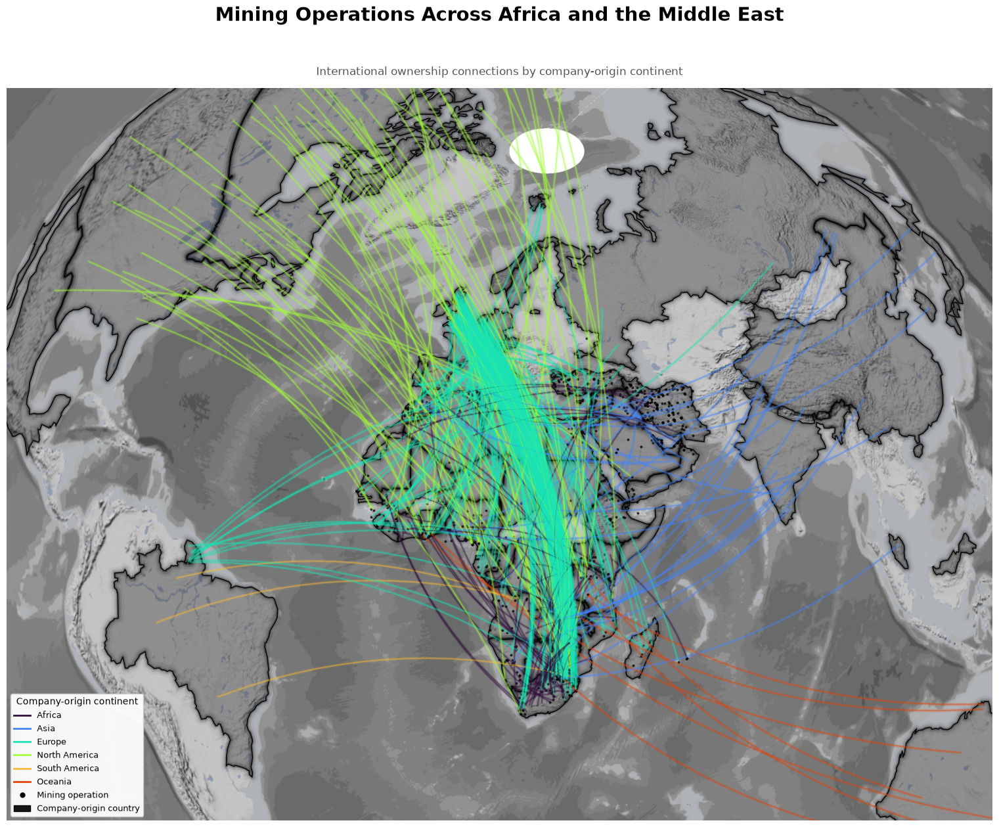

In [93]:

# ============================================================
# MINING OPERATIONS + INTERNATIONAL COMPANY-ORIGIN MAP
# COMPLETE UPDATED PLOTTING CELL
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from shapely.geometry import (
    Point,
    Polygon,
    MultiPolygon,
    GeometryCollection
)

from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D


# ============================================================
# 1. SETTINGS
# ============================================================

output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

# Map projection
target_crs = (
    "+proj=aeqd +lat_0=-5 +lon_0=25 "
    "+datum=WGS84 +units=m +no_defs"
)

# Stable random endpoints
rng = np.random.default_rng(42)

# Mine point appearance
MINE_POINT_SIZE = 3.5
MINE_POINT_ALPHA = 0.7

# Connection appearance
LINE_CURVE = 0.16

# Thinner glow and center lines
LINE_GLOW_WIDTH = 3.5
LINE_INNER_GLOW_WIDTH = 1.5
LINE_CORE_WIDTH = 0.55

# Glow transparency
OUTER_GLOW_ALPHA = 0.14
INNER_GLOW_ALPHA = 0.38

# Map extent margins
X_MARGIN_PERCENT = 0.025
Y_MARGIN_PERCENT = 0.035


# ============================================================
# 2. CHECK INPUT DATA
# ============================================================

required_objects = [
    "mines_for_map",
    "matched_countries",
    "origin_points",
    "world"
]

for object_name in required_objects:
    if object_name not in globals():
        raise NameError(
            f"Missing {object_name}. "
            "Run the earlier data-preparation cells first."
        )

required_columns = [
    "OWNERSHIP_RELATION",
    "OWNER_ORIGIN_COUNTRY"
]

missing_columns = [
    col for col in required_columns
    if col not in mines_for_map.columns
]

if missing_columns:
    raise ValueError(
        f"mines_for_map is missing: {missing_columns}"
    )

print("Input data checks passed.")


# ============================================================
# 3. PROJECT MINES AND ORIGIN POINTS
# ============================================================

mines_projected = mines_for_map.to_crs(target_crs).copy()

origin_points_projected = origin_points.to_crs(target_crs).copy()

print("\nMining operations:", len(mines_projected))
print("Origin points:", len(origin_points_projected))


# ============================================================
# 4. FILL HOLES IN ORIGIN COUNTRY POLYGONS
# ============================================================

# IMPORTANT:
# Remove interior rings BEFORE projecting the country geometries.
# This includes interior holes that may appear near polar regions.

origins_clean = matched_countries.copy()


def extract_polygons(geometry):

    if geometry is None or geometry.is_empty:
        return []

    if isinstance(geometry, Polygon):
        return [geometry]

    if isinstance(geometry, (MultiPolygon, GeometryCollection)):

        polygons = []

        for part in geometry.geoms:
            polygons.extend(extract_polygons(part))

        return polygons

    return []


def fill_polygon_holes(geometry):

    if geometry is None or geometry.is_empty:
        return geometry

    original_geometry = geometry

    try:

        polygon_parts = extract_polygons(geometry)

        if not polygon_parts:
            return original_geometry

        filled_polygons = []

        for polygon in polygon_parts:

            try:
                # Keep exterior ring and remove all interior rings.
                filled = Polygon(polygon.exterior)

                if not filled.is_empty:
                    filled_polygons.append(filled)

            except Exception:
                # Preserve this polygon if reconstruction fails.
                filled_polygons.append(polygon)

        if len(filled_polygons) == 1:
            return filled_polygons[0]

        if len(filled_polygons) > 1:
            return MultiPolygon(filled_polygons)

        return original_geometry

    except Exception:
        return original_geometry


# Apply hole filling in the original geographic CRS.
origins_clean["geometry"] = (
    origins_clean.geometry.apply(fill_polygon_holes)
)

origins_clean = origins_clean[
    origins_clean.geometry.notna()
    & ~origins_clean.geometry.is_empty
].copy()

print(
    "\nOrigin polygons after hole filling:",
    len(origins_clean)
)


# ============================================================
# 5. PROJECT CLEANED COUNTRY POLYGONS
# ============================================================

origins_projected = origins_clean.to_crs(target_crs).copy()

print(
    "Origin country polygons projected:",
    len(origins_projected)
)


# ============================================================
# 6. ASSIGN CONTINENTS — TURBO COLOR PALETTE
# ============================================================

admin_to_continent = dict(
    zip(world["ADMIN"], world["CONTINENT"])
)

origins_projected["CONTINENT"] = (
    origins_projected["ADMIN"].map(admin_to_continent)
)

print("\nCountries without continent:")
print(
    origins_projected.loc[
        origins_projected["CONTINENT"].isna(),
        ["OWNER_ORIGIN_COUNTRY", "ADMIN"]
    ]
)

# Turbo colormap: assign a distinct Turbo color to each continent.
continents = [
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America",
    "Oceania",
    "Antarctica"
]

turbo = plt.colormaps["turbo"]

continent_colors = {
    continent: turbo(i / (len(continents) - 1))
    for i, continent in enumerate(continents)
}

country_to_continent = dict(
    zip(
        origins_projected["OWNER_ORIGIN_COUNTRY"],
        origins_projected["CONTINENT"]
    )
)

origin_polygon_lookup = dict(
    zip(
        origins_projected["OWNER_ORIGIN_COUNTRY"],
        origins_projected.geometry
    )
)

# ============================================================
# 7. SELECT INTERNATIONAL MINING OPERATIONS
# ============================================================

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International")
    & mines_projected["OWNER_ORIGIN_COUNTRY"].notna()
].copy()

international_projected["ORIGIN_CONTINENT"] = (
    international_projected["OWNER_ORIGIN_COUNTRY"].map(
        country_to_continent
    )
)

international_projected["LINE_COLOR"] = (
    international_projected["ORIGIN_CONTINENT"].map(
        continent_colors
    )
)

# Retain operations with a matched origin polygon and continent.
international_projected = international_projected[
    international_projected["OWNER_ORIGIN_COUNTRY"].isin(
        origin_polygon_lookup.keys()
    )
    & international_projected["LINE_COLOR"].notna()
].copy()

print(
    "\nInternational operations with mapped origins:",
    len(international_projected)
)


# ============================================================
# 8. GENERATE RANDOM POINTS INSIDE ORIGIN COUNTRIES
# ============================================================

def random_point_inside(geometry, rng):

    """
    Generate a random point inside an origin-country polygon.

    These are visual connection endpoints only.
    They do not represent company headquarters.
    """

    if geometry is None or geometry.is_empty:
        return None

    polygon_parts = extract_polygons(geometry)

    if not polygon_parts:
        return None

    areas = np.array([
        polygon.area for polygon in polygon_parts
    ])

    if areas.sum() <= 0:
        return None

    probabilities = areas / areas.sum()

    selected_index = rng.choice(
        len(polygon_parts),
        p=probabilities
    )

    selected_polygon = polygon_parts[selected_index]

    minx, miny, maxx, maxy = selected_polygon.bounds

    for _ in range(2000):

        candidate = Point(
            rng.uniform(minx, maxx),
            rng.uniform(miny, maxy)
        )

        if selected_polygon.covers(candidate):
            return candidate

    return selected_polygon.representative_point()


international_projected["RANDOM_ORIGIN_POINT"] = (
    international_projected["OWNER_ORIGIN_COUNTRY"].apply(
        lambda country: random_point_inside(
            origin_polygon_lookup.get(country),
            rng
        )
    )
)

international_projected = international_projected[
    international_projected["RANDOM_ORIGIN_POINT"].notna()
].copy()

print(
    "Connections ready:",
    len(international_projected)
)


# ============================================================
# 9. CALCULATE MAP EXTENT
# ============================================================

# Use mining locations and origin representative points.
# Do NOT use full country polygon bounds: those can create
# an excessively large or distorted map extent.

mine_bounds = mines_projected.total_bounds
origin_bounds = origin_points_projected.total_bounds

xmin = min(mine_bounds[0], origin_bounds[0])
ymin = min(mine_bounds[1], origin_bounds[1])

xmax = max(mine_bounds[2], origin_bounds[2])
ymax = max(mine_bounds[3], origin_bounds[3])

x_range = xmax - xmin
y_range = ymax - ymin

xmin -= x_range * X_MARGIN_PERCENT
xmax += x_range * X_MARGIN_PERCENT

ymin -= y_range * Y_MARGIN_PERCENT
ymax += y_range * Y_MARGIN_PERCENT

print("\nMap extent:")
print("X:", xmin, xmax)
print("Y:", ymin, ymax)


# ============================================================
# 10. CREATE FIGURE AND BASEMAP
# ============================================================

fig, ax = plt.subplots(figsize=(18, 13))

# Initial extent.
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/tiles/256/"
    f"{{z}}/{{x}}/{{y}}?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    reset_extent=False,
    attribution=False
)

# Restore exact intended extent after basemap rendering.
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)


# ============================================================
# 11. DRAW ORIGIN COUNTRY POLYGONS
# ============================================================

# Dark filled company-origin countries.
origins_projected.plot(
    ax=ax,
    facecolor="#171717",
    edgecolor="none",
    alpha=0.30,
    zorder=2
)

# Layered black boundary glow.
for linewidth, alpha in [
    (13, 0.045),
    (8, 0.10),
    (4, 0.22),
    (1.2, 0.95)
]:

    origins_projected.boundary.plot(
        ax=ax,
        color="#050505",
        linewidth=linewidth,
        alpha=alpha,
        zorder=3
    )


# ============================================================
# 12. DRAW MINE POINTS FIRST
# ============================================================

# Points are drawn BEFORE the lines so the connections
# visually sit above them.

mines_projected.plot(
    ax=ax,
    color="#050505",
    marker="o",
    markersize=MINE_POINT_SIZE,
    alpha=MINE_POINT_ALPHA,
    zorder=4
)


# ============================================================
# 13. DRAW THIN GLOWING INTERNATIONAL CONNECTIONS
# ============================================================

for _, row in international_projected.iterrows():

    mine_point = row.geometry
    origin_point = row["RANDOM_ORIGIN_POINT"]
    line_color = row["LINE_COLOR"]

    if mine_point is None or origin_point is None:
        continue

    if mine_point.is_empty or origin_point.is_empty:
        continue

    start = (mine_point.x, mine_point.y)
    end = (origin_point.x, origin_point.y)

    # --------------------------------------------------------
    # OUTER GLOW
    # --------------------------------------------------------

    outer_glow = FancyArrowPatch(
        start,
        end,
        connectionstyle=f"arc3,rad={LINE_CURVE}",
        arrowstyle="-",
        linewidth=LINE_GLOW_WIDTH,
        color=line_color,
        alpha=OUTER_GLOW_ALPHA,
        zorder=5,
        capstyle="round"
    )

    ax.add_patch(outer_glow)

    # --------------------------------------------------------
    # INNER GLOW
    # --------------------------------------------------------

    inner_glow = FancyArrowPatch(
        start,
        end,
        connectionstyle=f"arc3,rad={LINE_CURVE}",
        arrowstyle="-",
        linewidth=LINE_INNER_GLOW_WIDTH,
        color=line_color,
        alpha=INNER_GLOW_ALPHA,
        zorder=6,
        capstyle="round"
    )

    ax.add_patch(inner_glow)

    # --------------------------------------------------------
    # THIN BRIGHT CENTER LINE
    # --------------------------------------------------------

    core_line = FancyArrowPatch(
        start,
        end,
        connectionstyle=f"arc3,rad={LINE_CURVE}",
        arrowstyle="-",
        linewidth=LINE_CORE_WIDTH,
        color=line_color,
        alpha=0.3,
        zorder=7,
        capstyle="round"
    )

    ax.add_patch(core_line)


# ============================================================
# 14. TITLE AND SUBTITLE
# ============================================================

fig.suptitle(
    "Mining Operations Across Africa and the Middle East",
    fontsize=21,
    fontweight="bold",
    x=0.5,
    y=0.965
)

ax.set_title(
    "International ownership connections by company-origin continent",
    fontsize=12,
    color="#555555",
    pad=14
)


# ============================================================
# 15. LEGEND
# ============================================================

legend_handles = []

for continent, color in continent_colors.items():

    if continent in international_projected["ORIGIN_CONTINENT"].values:

        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=color,
                linewidth=2,
                label=continent
            )
        )

legend_handles.append(
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#050505",
        markeredgecolor="#050505",
        markersize=5,
        label="Mining operation"
    )
)

legend_handles.append(
    Patch(
        facecolor="#171717",
        edgecolor="#050505",
        label="Company-origin country"
    )
)

ax.legend(
    handles=legend_handles,
    title="Company-origin continent",
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    framealpha=0.95,
    fontsize=9,
    title_fontsize=10
)


# ============================================================
# 16. FINAL FORMATTING
# ============================================================

ax.set_axis_off()

# Preserve exact map extent.
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.tight_layout(rect=[0, 0, 1, 0.94])




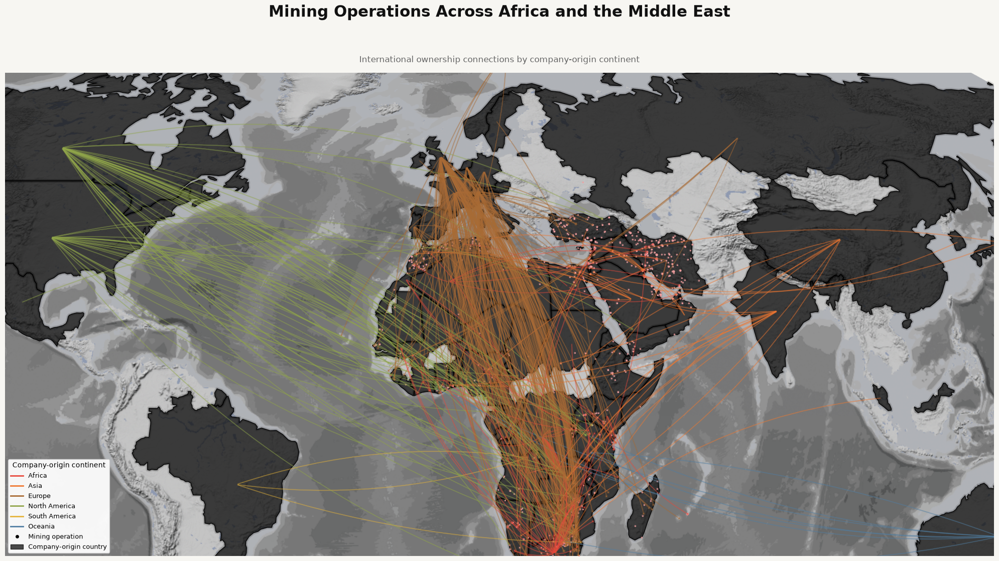

International operations: 466
Origin countries: 80
Saved: outputs/mining_company_origins_robinson_glow.png
Saved: outputs/mining_company_origins_robinson_glow.pdf


In [112]:

# ============================================================
# MINING OPERATIONS ACROSS AFRICA AND THE MIDDLE EAST
# Robinson projection | Mapbox basemap | Glowing connections
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from shapely.geometry import (
    Point, Polygon, MultiPolygon, GeometryCollection
)

from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D


# ============================================================
# 1. SETTINGS
# ============================================================

output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

# Robinson projection centered on the Prime Meridian
target_crs = (
    "+proj=robin +lon_0=0 "
    "+datum=WGS84 +units=m +no_defs"
)

rng = np.random.default_rng(42)

# Your existing Mapbox style
MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

# Origin country styling
ORIGIN_FILL = "#050505"
ORIGIN_ALPHA = 0.72

COUNTRY_GLOW_WIDTH = 5.0
COUNTRY_GLOW_ALPHA = 0.13
COUNTRY_EDGE_WIDTH = 0.85

# Mine points
MINE_POINT_SIZE = 3.5
MINE_POINT_ALPHA = 0.38

# Connection lines
LINE_CURVE_MIN = 0.07
LINE_CURVE_MAX = 0.20

LINE_GLOW_WIDTH = 2.5
LINE_INNER_GLOW_WIDTH = 1.4
LINE_CORE_WIDTH = 0.35

OUTER_GLOW_ALPHA = 0.08
INNER_GLOW_ALPHA = 0.22
CORE_ALPHA = 0.85


# ============================================================
# 2. CHECK REQUIRED DATA
# ============================================================

required_objects = [
    "mines_for_map",
    "matched_countries",
    "world",
    "MAPBOX_TOKEN"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"Missing {name}. Run the cell that creates this variable first."
        )

required_mine_columns = [
    "OWNERSHIP_RELATION",
    "OWNER_ORIGIN_COUNTRY"
]

for column in required_mine_columns:
    if column not in mines_for_map.columns:
        raise KeyError(f"Missing mine data column: {column}")

required_origin_columns = [
    "OWNER_ORIGIN_COUNTRY",
    "ADMIN",
    "geometry"
]

for column in required_origin_columns:
    if column not in matched_countries.columns:
        raise KeyError(f"Missing origin data column: {column}")


# ============================================================
# 3. COUNTRY GEOMETRY HELPERS
# ============================================================

def extract_polygons(geometry):

    if geometry is None or geometry.is_empty:
        return []

    if isinstance(geometry, Polygon):
        return [geometry]

    if isinstance(geometry, (MultiPolygon, GeometryCollection)):

        polygons = []

        for part in geometry.geoms:
            polygons.extend(extract_polygons(part))

        return polygons

    return []


def fill_polygon_holes(geometry):

    if geometry is None or geometry.is_empty:
        return geometry

    try:

        polygons = extract_polygons(geometry)

        if not polygons:
            return geometry

        filled_polygons = []

        for polygon in polygons:

            try:
                filled = Polygon(polygon.exterior)

                if not filled.is_empty:
                    filled_polygons.append(filled)

            except Exception:
                filled_polygons.append(polygon)

        if len(filled_polygons) == 1:
            return filled_polygons[0]

        if len(filled_polygons) > 1:
            return MultiPolygon(filled_polygons)

        return geometry

    except Exception:
        return geometry


# ============================================================
# 4. PREPARE ORIGINAL DATA BEFORE PROJECTING
# ============================================================

# Start from the original geographic geometries.
# Do not reuse geometries projected under the old projection.

origins_clean = matched_countries.copy()

origins_clean["geometry"] = (
    origins_clean.geometry.apply(fill_polygon_holes)
)

origins_clean = origins_clean[
    origins_clean.geometry.notna()
    & ~origins_clean.geometry.is_empty
].copy()

# Remove Antarctica from the origin-country display.
origins_clean = origins_clean[
    origins_clean["OWNER_ORIGIN_COUNTRY"] != "Antarctica"
].copy()

# Reproject the original data into the new Robinson projection.
origins_projected = origins_clean.to_crs(target_crs)

mines_projected = mines_for_map.to_crs(target_crs).copy()


# ============================================================
# 5. ASSIGN CONTINENTS TO ORIGIN COUNTRIES
# ============================================================

admin_to_continent = dict(
    zip(
        world["ADMIN"],
        world["CONTINENT"]
    )
)

origins_projected["CONTINENT"] = (
    origins_projected["ADMIN"].map(admin_to_continent)
)

country_to_continent = dict(
    zip(
        origins_projected["OWNER_ORIGIN_COUNTRY"],
        origins_projected["CONTINENT"]
    )
)

origin_polygon_lookup = dict(
    zip(
        origins_projected["OWNER_ORIGIN_COUNTRY"],
        origins_projected.geometry
    )
)


# ============================================================
# 6. TURBO COLOR PALETTE
# ============================================================

# continents = [
#     "Africa",
#     "Asia",
#     "Europe",
#     "North America",
#     "South America",
#     "Oceania",
#     "Antarctica"
# ]


continent_colors = {
    "Africa": "#E84A3C",
    "Asia": "#F07832",
    "Europe": "#A96B35",
    "North America": "#91A64B",
    "South America": "#E5B43B",
    "Oceania": "#527FA3",
    "Antarctica": "#527FA3"
}
# ============================================================
# 7. SELECT INTERNATIONAL MINING OPERATIONS
# ============================================================

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International")
    & mines_projected["OWNER_ORIGIN_COUNTRY"].notna()
].copy()

international_projected["ORIGIN_CONTINENT"] = (
    international_projected["OWNER_ORIGIN_COUNTRY"].map(
        country_to_continent
    )
)

international_projected["LINE_COLOR"] = (
    international_projected["ORIGIN_CONTINENT"].map(
        continent_colors
    )
)

international_projected = international_projected[
    international_projected["OWNER_ORIGIN_COUNTRY"].isin(
        origin_polygon_lookup.keys()
    )
    & international_projected["LINE_COLOR"].notna()
].copy()


# ============================================================
# 8. RANDOM ENDPOINTS INSIDE ORIGIN COUNTRIES
# ============================================================

def random_point_inside(geometry, rng):

    if geometry is None or geometry.is_empty:
        return None

    polygons = extract_polygons(geometry)

    if not polygons:
        return None

    areas = np.array([
        polygon.area for polygon in polygons
    ])

    if areas.sum() <= 0:
        return None

    polygon = rng.choice(
        polygons,
        p=areas / areas.sum()
    )

    minx, miny, maxx, maxy = polygon.bounds

    for _ in range(1500):

        candidate = Point(
            rng.uniform(minx, maxx),
            rng.uniform(miny, maxy)
        )

        if polygon.covers(candidate):
            return candidate

    return polygon.representative_point()


# Use an object array for Shapely geometry assignment.
random_endpoints = np.empty(
    len(international_projected),
    dtype=object
)

for position, (_, row) in enumerate(
    international_projected.iterrows()
):

    country = row["OWNER_ORIGIN_COUNTRY"]

    random_endpoints[position] = random_point_inside(
        origin_polygon_lookup[country],
        rng
    )

international_projected["RANDOM_ORIGIN_POINT"] = random_endpoints

international_projected = international_projected[
    international_projected["RANDOM_ORIGIN_POINT"].notna()
].copy()


# ============================================================
# 9. CALCULATE MAP EXTENT
# ============================================================

mine_bounds = mines_projected.total_bounds

# origin_point_geometries = gpd.GeoSeries(
#     international_projected["RANDOM_ORIGIN_POINT"],
#     crs=target_crs
# )

# origin_bounds = origin_point_geometries.total_bounds

# xmin = min(mine_bounds[0], origin_bounds[0])
# ymin = min(mine_bounds[1], origin_bounds[1])
# xmax = max(mine_bounds[2], origin_bounds[2])
# ymax = max(mine_bounds[3], origin_bounds[3])

origin_point_lookup = {
    row["OWNER_ORIGIN_COUNTRY"]: row.geometry.representative_point()
    for _, row in origins_projected.iterrows()
}

origin_points_array = np.empty(
    len(international_projected),
    dtype=object
)

for position, (_, row) in enumerate(international_projected.iterrows()):

    country = row["OWNER_ORIGIN_COUNTRY"]

    origin_points_array[position] = origin_point_lookup.get(country)

international_projected["RANDOM_ORIGIN_POINT"] = origin_points_array


# Slightly closer view
zoom_factor = 0.95

center_x = (xmin + xmax) / 2
center_y = (ymin + ymax) / 2

half_width = (xmax - xmin) * zoom_factor / 2
half_height = (ymax - ymin) * zoom_factor / 2

xmin = center_x - half_width
xmax = center_x + half_width
ymin = center_y - half_height
ymax = center_y + half_height


# ============================================================
# 10. CREATE MAP AND LOAD YOUR MAPBOX BASEMAP
# ============================================================

fig, ax = plt.subplots(figsize=(20, 12))

fig.patch.set_facecolor("#f7f6f2")
ax.set_facecolor("#f7f6f2")

# Set map bounds BEFORE loading tiles.
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/tiles/256/"
    f"{{z}}/{{x}}/{{y}}?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    reset_extent=False,
    attribution=False,
    zorder=0
)

# Restore intended extent after basemap loading.
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)


# ============================================================
# 11. DRAW ORIGIN COUNTRY GLOWS
# ============================================================

# Outer soft black glow
origins_projected.boundary.plot(
    ax=ax,
    color="#000000",
    linewidth=COUNTRY_GLOW_WIDTH,
    alpha=COUNTRY_GLOW_ALPHA,
    zorder=3
)

# Inner glow
origins_projected.boundary.plot(
    ax=ax,
    color="#000000",
    linewidth=2.0,
    alpha=0.24,
    zorder=3.1
)

# Semi-transparent black country fill
origins_projected.plot(
    ax=ax,
    facecolor=ORIGIN_FILL,
    edgecolor="none",
    alpha=ORIGIN_ALPHA,
    zorder=3.2
)

# Sharp boundary
origins_projected.boundary.plot(
    ax=ax,
    color="#000000",
    linewidth=COUNTRY_EDGE_WIDTH,
    alpha=0.95,
    zorder=3.3
)


# ============================================================
# 12. DRAW MINE POINTS
#     NON-INTERNATIONAL: PALE RED GLOW
#     INTERNATIONAL: MATCHING LINE COLOR + HALO
# ============================================================

# ------------------------------------------------------------
# A. Separate international and non-international mines
# ------------------------------------------------------------

international_indices = international_projected.index

other_mines = mines_projected.loc[
    ~mines_projected.index.isin(international_indices)
].copy()


# ------------------------------------------------------------
# B. Non-international mines: very light red glow
# ------------------------------------------------------------

# Outer red halo
ax.scatter(
    other_mines.geometry.x,
    other_mines.geometry.y,
    s=14,
    color="#F2A0A0",
    alpha=0.13,
    edgecolors="none",
    zorder=3.9
)

# Tiny pale-red center
other_mines.plot(
    ax=ax,
    color="#F2A0A0",
    marker="o",
    markersize=2,
    alpha=0.65,
    zorder=4
)


# ------------------------------------------------------------
# C. International mines: tiny matching colored dots + halos
# ------------------------------------------------------------

for _, row in international_projected.iterrows():

    point = row.geometry
    color = row["LINE_COLOR"]

    if point is None or point.is_empty:
        continue

    # Outer soft halo
    ax.scatter(
        point.x,
        point.y,
        s=24,
        color=color,
        alpha=0.12,
        edgecolors="none",
        zorder=4.5
    )

    # Inner halo
    ax.scatter(
        point.x,
        point.y,
        s=9,
        color=color,
        alpha=0.28,
        edgecolors="none",
        zorder=4.6
    )

    # Tiny crisp colored point
    ax.scatter(
        point.x,
        point.y,
        s=2,
        color=color,
        alpha=1.0,
        edgecolors="none",
        zorder=4.7
    )
# ============================================================
# 13. DRAW GLOWING INTERNATIONAL CONNECTIONS
# ============================================================

for line_number, (_, row) in enumerate(
    international_projected.iterrows()
):

    mine_point = row.geometry
    origin_point = row["RANDOM_ORIGIN_POINT"]

    if mine_point is None or origin_point is None:
        continue

    if mine_point.is_empty or origin_point.is_empty:
        continue

    start = (mine_point.x, mine_point.y)
    end = (origin_point.x, origin_point.y)

    color = row["LINE_COLOR"]

    # Stable curve variation for each connection.
    curve_rng = np.random.default_rng(line_number + 42)

    curve = curve_rng.uniform(
        LINE_CURVE_MIN,
        LINE_CURVE_MAX
    )

    if curve_rng.random() < 0.5:
        curve *= -1

    connectionstyle = f"arc3,rad={curve}"

    # Outer glow
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            connectionstyle=connectionstyle,
            arrowstyle="-",
            linewidth=LINE_GLOW_WIDTH,
            color=color,
            alpha=OUTER_GLOW_ALPHA,
            zorder=5,
            capstyle="round"
        )
    )

    # Inner glow
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            connectionstyle=connectionstyle,
            arrowstyle="-",
            linewidth=LINE_INNER_GLOW_WIDTH,
            color=color,
            alpha=INNER_GLOW_ALPHA,
            zorder=6,
            capstyle="round"
        )
    )

    # Bright central line
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            connectionstyle=connectionstyle,
            arrowstyle="-",
            linewidth=LINE_CORE_WIDTH,
            color=color,
            alpha=CORE_ALPHA,
            zorder=7,
            capstyle="round"
        )
    )


# ============================================================
# 14. TITLE AND SUBTITLE
# ============================================================

fig.suptitle(
    "Mining Operations Across Africa and the Middle East",
    fontsize=22,
    fontweight="bold",
    x=0.5,
    y=0.965,
    color="#111111"
)

ax.set_title(
    "International ownership connections by company-origin continent",
    fontsize=12,
    color="#666666",
    pad=15
)


# ============================================================
# 15. LEGEND
# ============================================================

legend_handles = []

for continent, color in continent_colors.items():

    if continent in international_projected[
        "ORIGIN_CONTINENT"
    ].values:

        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=color,
                linewidth=2,
                label=continent
            )
        )

legend_handles.extend([
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#050505",
        markeredgecolor="#050505",
        markersize=4,
        label="Mining operation"
    ),
    Patch(
        facecolor=ORIGIN_FILL,
        edgecolor="#000000",
        alpha=ORIGIN_ALPHA,
        label="Company-origin country"
    )
])

ax.legend(
    handles=legend_handles,
    title="Company-origin continent",
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    framealpha=0.94,
    fontsize=9,
    title_fontsize=10
)


# ============================================================
# 16. FINAL FORMATTING AND EXPORT
# ============================================================

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_axis_off()

plt.tight_layout(rect=[0, 0, 1, 0.94])

# png_path = os.path.join(
#     output_folder,
#     "mining_company_origins_robinson_glow.png"
# )

# pdf_path = os.path.join(
#     output_folder,
#     "mining_company_origins_robinson_glow.pdf"
# )

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("International operations:", len(international_projected))
print("Origin countries:", len(origins_projected))
print("Saved:", png_path)
print("Saved:", pdf_path)


Saved SVG: outputs/mining_company_origins_robinson_glow.svg


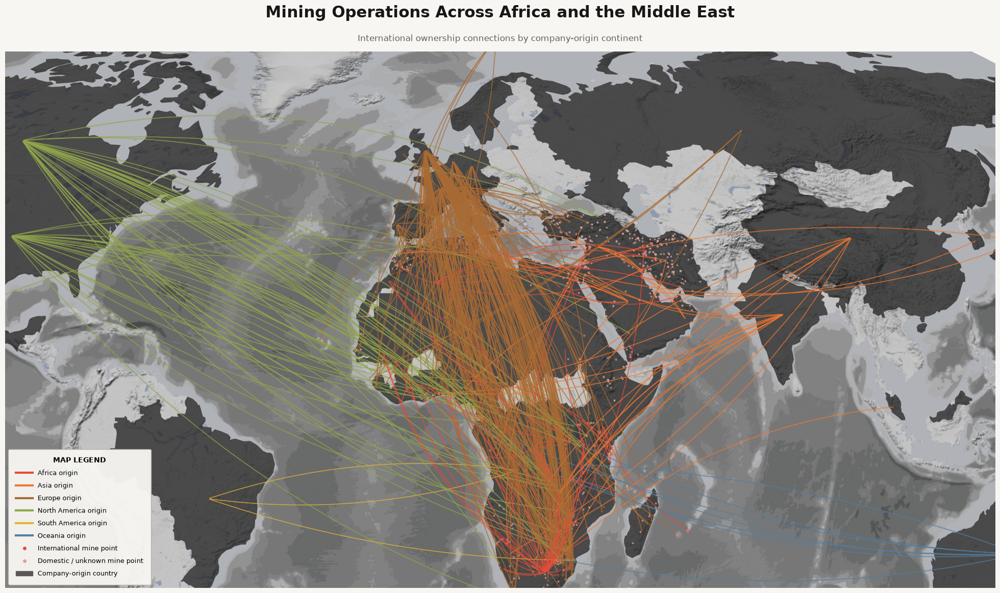

MAP COMPLETE
------------------------------------
Total mining operations: 1451
International operations mapped: 466
Non-international operations: 985
Origin countries displayed: 80
Unique company-origin countries: 51
Continents represented: 6
------------------------------------
Saved PNG: outputs/mining_company_origins_robinson_glow.png
Saved PDF: outputs/mining_company_origins_robinson_glow.pdf


In [120]:

# ============================================================
# MINING OPERATIONS ACROSS AFRICA AND THE MIDDLE EAST
# Robinson projection | Mapbox basemap | Glowing connections
# Fixed origin-country connection points | Updated legend
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from shapely.geometry import (
    Point, Polygon, MultiPolygon, GeometryCollection
)

from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D


# ============================================================
# 1. SETTINGS
# ============================================================

output_folder = "outputs"
os.makedirs(output_folder, exist_ok=True)

png_path = os.path.join(
    output_folder,
    "mining_company_origins_robinson_glow.png"
)

pdf_path = os.path.join(
    output_folder,
    "mining_company_origins_robinson_glow.pdf"
)

# Robinson projection centered on the Prime Meridian
target_crs = (
    "+proj=robin +lon_0=0 "
    "+datum=WGS84 +units=m +no_defs"
)

# Mapbox style
MAPBOX_USERNAME = "sophiameyers"
MAPBOX_STYLE_ID = "cmw04pvs3008t01p89yal70a0"

# Origin country styling: NO BLACK GLOW
ORIGIN_FILL = "#171717"
ORIGIN_ALPHA = 0.70
ORIGIN_EDGE = "#45413D"
ORIGIN_EDGE_WIDTH = 0.55

# Non-international mine points
NON_INT_COLOR = "#D9A09A"

# Connection curve settings
LINE_CURVE_MIN = 0.07
LINE_CURVE_MAX = 0.20

LINE_GLOW_WIDTH = 2.5
LINE_INNER_GLOW_WIDTH = 0.9
LINE_CORE_WIDTH = 0.35

OUTER_GLOW_ALPHA = 0.08
INNER_GLOW_ALPHA = 0.8
CORE_ALPHA = 0.85



# Map extent
ZOOM_FACTOR = 0.95

# Artistic continent palette
continent_colors = {
    "Africa": "#E84A3C",
    "Asia": "#F07832",
    "Europe": "#A96B35",
    "North America": "#91A64B",
    "South America": "#E5B43B",
    "Oceania": "#527FA3",
    "Antarctica": "#527FA3"
}


# ============================================================
# 2. CHECK REQUIRED DATA
# ============================================================

required_objects = [
    "mines_for_map",
    "matched_countries",
    "world",
    "MAPBOX_TOKEN"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"Missing {name}. Run the cell that creates this variable first."
        )

required_mine_columns = [
    "OWNERSHIP_RELATION",
    "OWNER_ORIGIN_COUNTRY"
]

for column in required_mine_columns:
    if column not in mines_for_map.columns:
        raise KeyError(f"Missing mine data column: {column}")

required_origin_columns = [
    "OWNER_ORIGIN_COUNTRY",
    "ADMIN",
    "geometry"
]

for column in required_origin_columns:
    if column not in matched_countries.columns:
        raise KeyError(f"Missing origin data column: {column}")


# ============================================================
# 3. COUNTRY GEOMETRY HELPERS
# ============================================================

def extract_polygons(geometry):

    if geometry is None or geometry.is_empty:
        return []

    if isinstance(geometry, Polygon):
        return [geometry]

    if isinstance(geometry, (MultiPolygon, GeometryCollection)):

        polygons = []

        for part in geometry.geoms:
            polygons.extend(extract_polygons(part))

        return polygons

    return []


def fill_polygon_holes(geometry):

    if geometry is None or geometry.is_empty:
        return geometry

    polygons = extract_polygons(geometry)

    if not polygons:
        return geometry

    filled_polygons = []

    for polygon in polygons:

        try:
            filled = Polygon(polygon.exterior)

            if not filled.is_empty:
                filled_polygons.append(filled)

        except Exception:
            filled_polygons.append(polygon)

    if len(filled_polygons) == 1:
        return filled_polygons[0]

    if len(filled_polygons) > 1:
        return MultiPolygon(filled_polygons)

    return geometry


# ============================================================
# 4. PREPARE ORIGINAL DATA BEFORE PROJECTING
# ============================================================

origins_clean = matched_countries.copy()

# Fill interior holes in origin-country polygons
origins_clean["geometry"] = (
    origins_clean.geometry.apply(fill_polygon_holes)
)

origins_clean = origins_clean[
    origins_clean.geometry.notna()
    & ~origins_clean.geometry.is_empty
].copy()

# Remove Antarctica
origins_clean = origins_clean[
    origins_clean["OWNER_ORIGIN_COUNTRY"] != "Antarctica"
].copy()

# Project original geometries
origins_projected = origins_clean.to_crs(target_crs)

mines_projected = (
    mines_for_map.to_crs(target_crs).copy()
)


# ============================================================
# 5. ASSIGN CONTINENTS TO ORIGIN COUNTRIES
# ============================================================

admin_to_continent = dict(
    zip(
        world["ADMIN"],
        world["CONTINENT"]
    )
)

origins_projected["CONTINENT"] = (
    origins_projected["ADMIN"].map(admin_to_continent)
)

country_to_continent = dict(
    zip(
        origins_projected["OWNER_ORIGIN_COUNTRY"],
        origins_projected["CONTINENT"]
    )
)

origin_polygon_lookup = dict(
    zip(
        origins_projected["OWNER_ORIGIN_COUNTRY"],
        origins_projected.geometry
    )
)


# ============================================================
# 6. SELECT INTERNATIONAL MINING OPERATIONS
# ============================================================

international_projected = mines_projected[
    (mines_projected["OWNERSHIP_RELATION"] == "International")
    & mines_projected["OWNER_ORIGIN_COUNTRY"].notna()
].copy()

# Assign the continent of each company's origin country
international_projected["ORIGIN_CONTINENT"] = (
    international_projected["OWNER_ORIGIN_COUNTRY"].map(
        country_to_continent
    )
)

# Assign the connection-line color
international_projected["LINE_COLOR"] = (
    international_projected["ORIGIN_CONTINENT"].map(
        continent_colors
    )
)

# Keep only operations with a mapped origin country
international_projected = international_projected[
    international_projected["OWNER_ORIGIN_COUNTRY"].isin(
        origin_polygon_lookup.keys()
    )
    & international_projected["LINE_COLOR"].notna()
].copy()


# ============================================================
# 7. CREATE ONE FIXED POINT PER ORIGIN COUNTRY
# ============================================================

# Every mine connected to the same country will use
# exactly the same representative point.

origin_point_lookup = {
    row["OWNER_ORIGIN_COUNTRY"]: row.geometry.representative_point()
    for _, row in origins_projected.iterrows()
}

# Assign one fixed endpoint to each international mine
origin_points_array = np.empty(
    len(international_projected),
    dtype=object
)

for position, (_, row) in enumerate(
    international_projected.iterrows()
):

    country = row["OWNER_ORIGIN_COUNTRY"]

    origin_points_array[position] = (
        origin_point_lookup.get(country)
    )

international_projected["ORIGIN_POINT"] = (
    origin_points_array
)

# Remove any records without a valid endpoint
international_projected = international_projected[
    international_projected["ORIGIN_POINT"].notna()
].copy()


# ============================================================
# 8. CALCULATE MAP EXTENT
# ============================================================

# Include all mine locations
mine_bounds = mines_projected.total_bounds

# Include all fixed origin-country endpoints
origin_point_geometries = gpd.GeoSeries(
    international_projected["ORIGIN_POINT"].tolist(),
    crs=target_crs
)

origin_bounds = origin_point_geometries.total_bounds

# Combine both sets of bounds
xmin = min(mine_bounds[0], origin_bounds[0])
ymin = min(mine_bounds[1], origin_bounds[1])
xmax = max(mine_bounds[2], origin_bounds[2])
ymax = max(mine_bounds[3], origin_bounds[3])

# Apply a slight zoom
center_x = (xmin + xmax) / 2
center_y = (ymin + ymax) / 2

half_width = (xmax - xmin) * ZOOM_FACTOR / 2
half_height = (ymax - ymin) * ZOOM_FACTOR / 2

xmin = center_x - half_width
xmax = center_x + half_width
ymin = center_y - half_height
ymax = center_y + half_height


# ============================================================
# 9. CREATE MAP AND LOAD MAPBOX BASEMAP
# ============================================================

fig, ax = plt.subplots(figsize=(20, 12))

fig.patch.set_facecolor("#F7F6F2")
ax.set_facecolor("#F7F6F2")

# Set bounds before loading map tiles
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

mapbox_url = (
    f"https://api.mapbox.com/styles/v1/"
    f"{MAPBOX_USERNAME}/{MAPBOX_STYLE_ID}/tiles/256/"
    f"{{z}}/{{x}}/{{y}}?access_token={MAPBOX_TOKEN}"
)

ctx.add_basemap(
    ax,
    source=mapbox_url,
    crs=target_crs,
    zoom=3,
    reset_extent=False,
    attribution=False,
    zorder=0
)

# Restore intended extent
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)


# ============================================================
# 10. DRAW ORIGIN COUNTRIES
#      NO BLACK GLOW
# ============================================================

# Draw the country polygons with a simple dark fill
origins_projected.plot(
    ax=ax,
    facecolor=ORIGIN_FILL,
    edgecolor=ORIGIN_EDGE,
    linewidth=ORIGIN_EDGE_WIDTH,
    alpha=ORIGIN_ALPHA,
    zorder=3
)


# ============================================================
# 11. SEPARATE INTERNATIONAL AND OTHER MINE POINTS
# ============================================================

international_indices = international_projected.index

other_mines = mines_projected.loc[
    ~mines_projected.index.isin(international_indices)
].copy()


# ============================================================
# 12. DRAW NON-INTERNATIONAL MINE POINTS
#      VERY LIGHT RED CENTER + MATCHING HALO
# ============================================================

# Outer pale-red halo
ax.scatter(
    other_mines.geometry.x,
    other_mines.geometry.y,
    s=14,
    color=NON_INT_COLOR,
    alpha=0.13,
    edgecolors="none",
    zorder=3.9
)

# Tiny pale-red center
other_mines.plot(
    ax=ax,
    color=NON_INT_COLOR,
    marker="o",
    markersize=2,
    alpha=0.65,
    zorder=4
)


# ============================================================
# 13. DRAW INTERNATIONAL MINE POINTS
#      TINY CONTINENT-COLORED CENTER + MATCHING HALO
# ============================================================

for _, row in international_projected.iterrows():

    point = row.geometry
    color = row["LINE_COLOR"]

    if point is None or point.is_empty:
        continue

    # Outer soft halo
    ax.scatter(
        point.x,
        point.y,
        s=24,
        color=color,
        alpha=0.12,
        edgecolors="none",
        zorder=4.5
    )

    # Inner halo
    ax.scatter(
        point.x,
        point.y,
        s=9,
        color=color,
        alpha=0.28,
        edgecolors="none",
        zorder=4.6
    )

    # Tiny crisp colored center
    ax.scatter(
        point.x,
        point.y,
        s=2,
        color=color,
        alpha=1.0,
        edgecolors="none",
        zorder=4.7
    )


# ============================================================
# 14. DRAW GLOWING INTERNATIONAL CONNECTIONS
# ============================================================

for line_number, (_, row) in enumerate(
    international_projected.iterrows()
):

    mine_point = row.geometry
    origin_point = row["ORIGIN_POINT"]

    if mine_point is None or origin_point is None:
        continue

    if mine_point.is_empty or origin_point.is_empty:
        continue

    start = (mine_point.x, mine_point.y)
    end = (origin_point.x, origin_point.y)

    color = row["LINE_COLOR"]

    # Stable curve variation
    curve_rng = np.random.default_rng(line_number + 42)

    curve = curve_rng.uniform(
        LINE_CURVE_MIN,
        LINE_CURVE_MAX
    )

    if curve_rng.random() < 0.5:
        curve *= -1

    connectionstyle = f"arc3,rad={curve}"

    # Outer glow
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            connectionstyle=connectionstyle,
            arrowstyle="-",
            linewidth=LINE_GLOW_WIDTH,
            color=color,
            alpha=OUTER_GLOW_ALPHA,
            zorder=5,
            capstyle="round"
        )
    )

    # Inner glow
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            connectionstyle=connectionstyle,
            arrowstyle="-",
            linewidth=LINE_INNER_GLOW_WIDTH,
            color=color,
            alpha=INNER_GLOW_ALPHA,
            zorder=6,
            capstyle="round"
        )
    )

    # Bright central line
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            connectionstyle=connectionstyle,
            arrowstyle="-",
            linewidth=LINE_CORE_WIDTH,
            color=color,
            alpha=CORE_ALPHA,
            zorder=7,
            capstyle="round"
        )
    )


# ============================================================
# 15. TITLE AND SUBTITLE
# ============================================================

fig.suptitle(
    "Mining Operations Across Africa and the Middle East",
    fontsize=22,
    fontweight="bold",
    x=0.5,
    y=0.965,
    color="#171717"
)

ax.set_title(
    "International ownership connections by company-origin continent",
    fontsize=12,
    color="#66615B",
    pad=15
)


# ============================================================
# 16. UPDATED LEGEND
# ============================================================

legend_handles = []

# ------------------------------------------------------------
# A. Continent-colored connection lines
# ------------------------------------------------------------

continent_order = [
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America",
    "Oceania"
]

present_continents = set(
    international_projected["ORIGIN_CONTINENT"].dropna()
)

for continent in continent_order:

    if continent not in present_continents:
        continue

    color = continent_colors[continent]

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=color,
            linewidth=3.0,
            alpha=1.0,
            label=f"{continent} origin"
        )
    )


# ------------------------------------------------------------
# B. International mine points
# ------------------------------------------------------------

legend_handles.append(
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        color="none",
        markerfacecolor="#E84A3C",
        markeredgecolor="none",
        markersize=5,
        label="International mine point"
    )
)


# ------------------------------------------------------------
# C. Domestic / unknown mine points
# ------------------------------------------------------------

legend_handles.append(
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        color="none",
        markerfacecolor=NON_INT_COLOR,
        markeredgecolor="none",
        markersize=5,
        label="Domestic / unknown mine point"
    )
)


# ------------------------------------------------------------
# D. Company-origin country polygons
# ------------------------------------------------------------

legend_handles.append(
    Patch(
        facecolor=ORIGIN_FILL,
        edgecolor=ORIGIN_EDGE,
        alpha=ORIGIN_ALPHA,
        label="Company-origin country"
    )
)


# ------------------------------------------------------------
# E. Display legend
# ------------------------------------------------------------

legend = ax.legend(
    handles=legend_handles,
    title="MAP LEGEND",
    loc="lower left",
    frameon=True,
    facecolor="#F7F6F2",
    edgecolor="#B8B2A8",
    framealpha=0.96,
    fontsize=9,
    title_fontsize=10,
    labelspacing=0.85,
    handlelength=2.6,
    borderpad=1.2
)

legend.get_title().set_fontweight("bold")


# ============================================================
# 17. FINAL FORMATTING AND EXPORT
# ============================================================

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_axis_off()

plt.tight_layout(rect=[0, 0, 1, 0.94])

# # Save high-resolution PNG
# fig.savefig(
#     png_path,
#     dpi=300,
#     bbox_inches="tight",
#     facecolor=fig.get_facecolor()
# )

# Save PDF
fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

svg_path = os.path.join(
    output_folder,
    "mining_company_origins_robinson_glow.svg"
)
fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    transparent=False,
    dpi=300
)
print("Saved SVG:", svg_path)
plt.show()
import matplotlib as mpl

mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["svg.image_inline"] = True
mpl.rcParams["path.simplify"] = False

# ============================================================
# 18. PRINT SUMMARY
# ============================================================

print("MAP COMPLETE")
print("------------------------------------")
print("Total mining operations:", len(mines_projected))
print("International operations mapped:", len(international_projected))
print("Non-international operations:", len(other_mines))
print("Origin countries displayed:", len(origins_projected))
print(
    "Unique company-origin countries:",
    international_projected["OWNER_ORIGIN_COUNTRY"].nunique()
)
print(
    "Continents represented:",
    international_projected["ORIGIN_CONTINENT"].nunique()
)
print("------------------------------------")
print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)
